# EOD electric-field solver — multi-fish, two-layer bodies, recorded waveform

Extends the single-fish resistive pipeline with:
- **Two-layer fish**: conductive **interior** + resistive/capacitive **skin** (literature values).
- **Recorded EOD** as the source waveform `I(t)` (first row, most active electrode).
- **Per-fish solve**: each of the 4 fish takes a turn as the emitter; the *other* fish enter as skin+interior boundaries.

Governing equation (frequency domain, one ω):
$$\nabla\cdot(\gamma\,\nabla\hat\varphi) = -\hat s,\qquad \gamma=\sigma+i\omega\varepsilon$$
solved per kept EOD frequency, then inverse-FFT to `φ(t)`.

In [1]:
import numpy as np, pandas as pd, re
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.ndimage import zoom, binary_erosion
import matplotlib.pyplot as plt

## 0. Load fish masks
`mask_example_3_frames.npy` -> `(n_frames, n_fish, P, P)`. We take frame 0 -> `(4, P, P)`.

In [93]:
# only 3 frames (0,600,800) chosen from video 
mgz_file = 'data/video2024-02-20T21_16_26__223e__59997__masks_packed.mgz'

# mask_example_3_frames = np.load('data/mask_example_3_frames.npy')
frame_number = 2
fish_mask = np.load(f'{mgz_file}_masks_first_1000_frames.npy')[:,frame_number]          # frame 0 -> (4, P, P) boolean
print("fish_mask:", fish_mask.shape, fish_mask.dtype)


fish_mask: (4, 912, 912) bool


In [94]:
# how fine the grid points on tank are:
N = 200
n_fish = 100 # how many points on fish

## 1. Grid bookkeeping + geometry (occupancy level-set, theta matrices)

In [95]:
def idx(i, j, N): return i * N + j
def to_grid(v, N): return np.asarray(v).reshape(N, N)

def mask_to_grid(m, N):
    """(P,P) bool -> (N,N) bool on the tank grid (nearest-neighbour, stays binary)."""
    P = m.shape[0]
    if P == N: return m.astype(bool)
    return zoom(m.astype(float), N / P, order=0)[:N, :N] > 0.5

from scipy.interpolate import UnivariateSpline

def fish_midline_from_mask(mask, n_ctrl=200, smooth=None):
    """(P,P) bool -> smooth curved midline (n_ctrl,2) in [0,1], tail->head."""
    xs, ys = np.nonzero(mask)
    pts = np.column_stack([xs, ys]).astype(float); c = pts.mean(0)
    v = np.linalg.svd(pts - c, full_matrices=False)[2][0]
    perp = np.array([-v[1], v[0]])
    t = (pts - c) @ v
    w = (pts - c) @ perp

    # average w at each unique t (spline needs strictly increasing x), weighted by count
    order = np.argsort(t); t_s, w_s = t[order], w[order]
    tu, inv, cnt = np.unique(np.round(t_s, 6), return_inverse=True, return_counts=True)
    wu = np.bincount(inv, weights=w_s) / cnt              # mean w per t column
    L = t_s.max() - t_s.min()

    # smoothing: s scales with number of points and data variance; larger -> smoother
    if smooth is None:
        smooth = len(tu) * (0.05 * L)**2                 # gentle default
    spl = UnivariateSpline(tu, wu, k=3, s=smooth, w=np.sqrt(cnt))  # weight by column mass
    ts = np.linspace(t_s.min(), t_s.max(), n_ctrl)
    curve = c + np.outer(ts, v) + np.outer(spl(ts), perp)

    # wlo = w[np.abs(t - t.min()) < 0.25*L].std()
    # whi = w[np.abs(t - t.max()) < 0.25*L].std()
    # if not (wlo < whi): curve = curve[::-1]              # orient tail->head

    # --- orient tail->head by AREA of each half (head end is bulkier) ---
    t_mid = 0.5 * (t.min() + t.max())
    area_lo = np.count_nonzero(t <  t_mid)      # pixels in the low-t half
    area_hi = np.count_nonzero(t >= t_mid)      # pixels in the high-t half
    # head = the half with MORE area; tail = the lighter half, placed first
    if area_lo > area_hi:                       # low-t end is the head -> reverse so tail is first
        curve = curve[::-1]

    nx, ny = mask.shape
    return curve / np.array([nx-1, ny-1])

# def multipole_sources(midline, n, I0=1.0):
#     """Distribute n+1 point currents evenly by ARC LENGTH along a curved midline.
#        midline: (M, 2) points tail->head in [0,1].  Returns (pos (n+1,2), currents (n+1,))."""
#     midline = np.asarray(midline, float)
#     seg = np.linalg.norm(np.diff(midline, axis=0), axis=1)
#     s = np.concatenate([[0.0], np.cumsum(seg)])           # cumulative arc length
#     s /= s[-1]                                            # normalize to [0,1]
#     targets = np.arange(n + 1) / n                        # even spacing along the body
#     pos = np.column_stack([np.interp(targets, s, midline[:, 0]),
#                            np.interp(targets, s, midline[:, 1])])
#     m = np.full(n + 1, 1.0/n); m[0] = -1.0               # tail sink, body sources
#     return pos, m * I0

def multipole_sources(midline, n, I0=1.0):
    """Distribute n+1 point currents evenly by ARC LENGTH along a curved midline.
       Total current scales with body length (sum of consecutive point distances).
       midline: (M, 2) points tail->head in [0,1]. Returns (pos (n+1,2), currents (n+1,))."""
    midline = np.asarray(midline, float)
    seg = np.linalg.norm(np.diff(midline, axis=0), axis=1)
    s = np.concatenate([[0.0], np.cumsum(seg)])           # cumulative arc length
    s /= s[-1]                                            # normalize to [0,1]
    targets = np.arange(n + 1) / n                        # even spacing along the body
    pos = np.column_stack([np.interp(targets, s, midline[:, 0]),
                           np.interp(targets, s, midline[:, 1])])

    # body length = sum of distances between consecutive placed points (approx fish length)
    length = np.linalg.norm(np.diff(pos, axis=0), axis=1).sum()

    m = np.full(n + 1, 1.0/n); m[0] = -1.0               # tail sink, body sources (sum = 0)
    return pos, m * I0 * length                          # <-- scale total current by length

## 2. Two-layer material: water / skin (resistive+capacitive) / interior (conductive)

**Literature-based, normalized values** (`sigma_water=1`):

| region | sigma | eps | basis |
|---|---|---|---|
| water | 1.0 | 0 | resistive; loss tan ~1e-3 at kHz |
| interior | 30 | 0 | body ~10-100x water, funnels current (Caputi/Budelli) |
| skin | 0.10 | 2.7e-6 | high sheet resistance + capacitance; tan~0.5 @3kHz |

Capacitance lives in the **skin** (that's what distorts the EOD waveform). Interior is conductive but not capacitive.

In [96]:
# Ratios from Migliaro/Caputi/Budelli 2005 (water = 16.5 uS/cm):
#   interior 3300 uS/cm  -> 200x water
#   skin     100 uS/cm^2 -> a SHEET conductance; bulk value depends on skin thickness
MAT = dict(
    sigma_water    = 1.0,     eps_water    = 0.0,      # water resistive (loss tan ~1e-3)
    sigma_interior = 200.0,   eps_interior = 0.0,      # body: 3300/16.5 = 200x water (measured)
    sigma_skin     = 0.05,    eps_skin     = 2.7e-6,   # skin: RESISTIVE; see note on thickness
)

def material_layers(masks, N, skip=None, skin_cells=1, **mat):
    """Returns sigma, eps (N,N) with 3 regions, plus per-fish (interior, skin) grids.
       Each fish: interior = eroded mask, skin = 1-cell rim. `skip` omits one fish
       (the emitter) so it acts as a pure multipole source in water."""
    if isinstance(masks, dict): masks = [masks[k] for k in sorted(masks)]
    sigma = np.full((N, N), mat['sigma_water'])
    eps   = np.full((N, N), mat['eps_water'])
    layers = {}
    for f, m in enumerate(masks):
        if (skip is not None and f == skip) or not np.any(m): continue
        body = mask_to_grid(m, N)
        interior = binary_erosion(body, iterations=skin_cells)
        skin = body & ~interior
        sigma[interior] = mat['sigma_interior']; eps[interior] = mat['eps_interior']
        sigma[skin]     = mat['sigma_skin'];     eps[skin]     = mat['eps_skin']
        layers[f] = (interior, skin)
    return sigma, eps, layers

## 3. Matrix assembly (complex, harmonic-mean face admittivity) + solver

Edge weight = complex harmonic mean of adjacent `gamma` (handles water|skin and skin|interior interfaces automatically). `A` is complex-symmetric -> **LU, not CG**.

In [97]:
# def build_A_gamma(gamma, N):
#     """div(gamma grad phi) = -s.  gamma_eff = 2 gC gM/(gC+gM) per edge.
#        Off-grid neighbour skipped -> Neumann wall."""
#     r, c, v = [], [], []
#     for i in range(N):
#         for j in range(N):
#             k = idx(i, j, N); ws = 0j
#             for di, dj in ((-1,0),(1,0),(0,-1),(0,1)):
#                 ii, jj = i+di, j+dj
#                 if 0 <= ii < N and 0 <= jj < N:
#                     ga, gb = gamma[i, j], gamma[ii, jj]
#                     w = 2.0*ga*gb/(ga+gb)
#                     r.append(k); c.append(idx(ii, jj, N)); v.append(w); ws += w
#             r.append(k); c.append(k); v.append(-ws)
#     return sp.coo_matrix((v, (r, c)), shape=(N*N, N*N), dtype=complex).tocsr()

# def build_A_gamma_theta(gamma, tx, ty, N):
#     """div(gamma grad phi) = -s with theta-weighted face admittivity:
#        gamma_eff = ( theta/gamma_C + (1-theta)/gamma_M )^-1  per edge (theta=1/2 -> harmonic mean).
#        tx[i,j] = crossing fraction on edge (i,j)->(i+1,j);  ty likewise along +y.
#        Off-grid neighbour skipped -> Neumann wall."""
#     r, c, v = [], [], []
#     def edge(k, kk, gC, gM, th):
#         w = gC if gC == gM else 1.0 / (th/gC + (1.0-th)/gM)        # theta-weighted; skip if same material
#         r.append(k); c.append(kk); v.append(w); return w
#     for i in range(N):
#         for j in range(N):
#             k = idx(i, j, N); ws = 0j
#             if i > 0:    ws += edge(k, idx(i-1, j, N), gamma[i, j], gamma[i-1, j], 1 - tx[i-1, j])
#             if i < N-1:  ws += edge(k, idx(i+1, j, N), gamma[i, j], gamma[i+1, j],     tx[i,   j])
#             if j > 0:    ws += edge(k, idx(i, j-1, N), gamma[i, j], gamma[i, j-1], 1 - ty[i, j-1])
#             if j < N-1:  ws += edge(k, idx(i, j+1, N), gamma[i, j], gamma[i, j+1],     ty[i,   j])
#             r.append(k); c.append(k); v.append(-ws)
#     return sp.coo_matrix((v, (r, c)), shape=(N*N, N*N), dtype=complex).tocsr()

def occupancy_field(masks, N, skip=None):
    """(n_fish,P,P) bool (or dict) -> smooth NxN occupancy in [0,1]; occ>0.5 = fish.
       order=1 (linear) interpolation keeps fractional values at the boundary, so the
       0.5-contour is the sub-cell fish outline that theta crossings are read from."""
    if isinstance(masks, dict):
        masks = [masks[k] for k in sorted(masks)]
    occ = np.zeros((N, N))
    for f, m in enumerate(masks):
        if (skip is not None and f == skip) or not np.any(m):
            continue
        P = m.shape[0]
        occ = np.maximum(occ, zoom(m.astype(float), N / P, order=1)[:N, :N])
    return occ

def _edge_weight(gC, gM, occC, occM, thc, delta_h, g_water, g_skin, g_interior):
    """Effective admittivity across one edge, composing water|skin|interior segments in series.
       thc = outer crossing fraction from node C (NaN if uncut).  delta_h = skin thickness / h."""
    if np.isnan(thc):                                  # no boundary on this edge
        return gC if gC == gM else 2*gC*gM/(gC+gM)     # (same-material -> gC; safety harmonic)
    inward = 1.0 if occM > occC else -1.0              # interior lies toward the more-occupied node
    th_in = thc + inward * delta_h                     # inner (skin|interior) crossing
    # collect crossings in (0,1), ordered from node C, with the material of each segment
    cuts = sorted([t for t in (thc, th_in) if 1e-6 < t < 1-1e-6])
    pts = [0.0] + cuts + [1.0]
    Z = 0.0
    for a, bb in zip(pts[:-1], pts[1:]):
        xm = 0.5*(a+bb)                                # segment midpoint (fraction from C)
        # occupancy at the midpoint decides the material: <outer=water, between=skin, >inner=interior
        # distance from C in "occupancy sense": compare midpoint to the two crossings
        d_out = (xm - thc)*inward                      # >0 => past the outer boundary (inside fish)
        d_in  = (xm - th_in)*inward                    # >0 => past the inner boundary (interior)
        g = g_water if d_out < 0 else (g_interior if d_in > 0 else g_skin)
        Z += (bb - a)/g
    return 1.0/Z

def theta_outer(occ, level=0.5):
    """Outer (water|fish) crossing fraction per edge, from the smooth occupancy level-set.
       Returns theta_x (edges along +x) and theta_y (along +y); NaN where the edge is uncut."""
    def cross(a, b):
        cut = (a - level) * (b - level) < 0
        d = a - b
        th = np.divide(a - level, d, out=np.full_like(a, np.nan), where=np.abs(d) > 1e-12)
        return np.where(cut, np.clip(th, 1e-6, 1 - 1e-6), np.nan)
    return cross(occ[:-1, :], occ[1:, :]), cross(occ[:, :-1], occ[:, 1:])

def build_A_shell(occ, N, delta_h, g_water, g_skin, g_interior):
    """theta-weighted complex A with a resolved skin SHELL: outer crossing from the
       level-set, inner crossing offset inward by the skin thickness delta_h."""
    tx, ty = theta_outer(occ)                          # outer crossings per edge
    gnode = np.where(occ > 0.5, g_interior, g_water)   # node materials (skin is sub-cell)
    r, c, v = [], [], []
    def edge(k, kk, gC, gM, oC, oM, thc):
        w = _edge_weight(gC, gM, oC, oM, thc, delta_h, g_water, g_skin, g_interior)
        r.append(k); c.append(kk); v.append(w); return w
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N); ws = 0j
            if i > 0:   ws += edge(k, idx(i-1,j,N), gnode[i,j], gnode[i-1,j], occ[i,j], occ[i-1,j], 1-tx[i-1,j])
            if i < N-1: ws += edge(k, idx(i+1,j,N), gnode[i,j], gnode[i+1,j], occ[i,j], occ[i+1,j],   tx[i,  j])
            if j > 0:   ws += edge(k, idx(i,j-1,N), gnode[i,j], gnode[i,j-1], occ[i,j], occ[i,j-1], 1-ty[i,j-1])
            if j < N-1: ws += edge(k, idx(i,j+1,N), gnode[i,j], gnode[i,j+1], occ[i,j], occ[i,j+1],   ty[i,  j])
            r.append(k); c.append(k); v.append(-ws)
    return sp.coo_matrix((v,(r,c)), shape=(N*N,N*N), dtype=complex).tocsr()

def solve_potential(A, b, pin=0):
    """Solve A phi = b (singular complex Neumann). Pin one node for the gauge."""
    M = (-A).tolil(); rhs = -(np.asarray(b).ravel().astype(complex))
    M[pin, :] = 0; M[pin, pin] = 1; rhs[pin] = 0
    phi = splu(M.tocsc()).solve(rhs)
    return phi - phi.mean()

## 4. Source: multipole (tail sink −1, body sources +1/n)

In [98]:
def place_current_on_grid(b, x, y, I, h, N):
    fi, fj = x/h, y/h; i, j = int(fi), int(fj); a, c = fi-i, fj-j
    for di, wx in ((0, 1-a), (1, a)):
        for dj, wy in ((0, 1-c), (1, c)):
            ii, jj = i+di, j+dj
            if 0 <= ii < N and 0 <= jj < N: b[ii, jj] += I*wx*wy

def build_multipole_b(pos, cur, h, N):
    b = np.zeros((N, N))
    for (x, y), Ii in zip(pos, cur): place_current_on_grid(b, x, y, Ii, h, N)
    return b - b.mean()

# Inspect EODs:

In [99]:
eod_csv = 'data/Data_4fish_2024-02-20T21_16_26.csv'
df_eod = pd.read_csv(eod_csv)
print(df_eod.iloc[25])

elec = list(range(10))
tim = list(range(25))

Frame                     2.000000
Time                      0.030582
chin_x_1                550.515000
chin_y_1                 26.909000
chin_score_1              1.000000
                           ...    
electrode_10_time_21      0.000504
electrode_10_time_22      0.000086
electrode_10_time_23      0.000243
electrode_10_time_24      0.000101
electrode_10_time_25      0.000116
Name: 25, Length: 312, dtype: float64


## 5. Recorded EOD -> I(t), and its power spectrum (pick frequencies that matter)

In [100]:
def load_eod_row(df, row=0, fs=20000.0):
    """Read one EOD from the CSV. Returns E (n_elec, n_time), best electrode idx, dt."""
    pat = re.compile(r"electrode_(\d+)_time_(\d+)")
    cells = [(int(m.group(1)), int(m.group(2)), col) for col in df.columns for m in [pat.match(col)] if m]
    ne = max(e for e,_,_ in cells); nt = max(t for _,t,_ in cells)
    E = np.full((ne, nt), np.nan)
    for e, t, col in cells: E[e-1, t-1] = df.iloc[row][col]
    best = int(np.argmax(E.std(axis=1)))                  # most active electrode
    return E, best, 1.0/fs

def eod_frequencies(I_rec, dt, power_keep=0.999, detrend=True):
    """Which rfft bins carry `power_keep` of the signal power. amplitude is irrelevant."""
    x = np.asarray(I_rec, float); x = x - x.mean() if detrend else x
    n = len(x); Ihat = np.fft.rfft(x); f = np.fft.rfftfreq(n, dt); Pw = np.abs(Ihat)**2
    order = np.argsort(Pw)[::-1]; frac = np.cumsum(Pw[order])/Pw.sum()
    nk = int(np.searchsorted(frac, power_keep)+1)
    keep = np.sort(order[:nk]); keep = keep[f[keep] > 0]  # drop DC
    return keep, 2*np.pi*f, Ihat, n, f, Pw

In [101]:
# electrode locations 
E_loc = pd.read_csv('data/electrodes_signed_px_coord_2024-02-13.csv')
print(E_loc)


   pair   x1   y1 pol1   x2   y2 pol2
0     1   88  880    -  456  873    +
1     2  494  873    +  838  866    -
2     3  887  797    -  881  461    +
3     4  879  410    -  887   48    +
4     5  828   12    +  490   18    -
5     6  429   20    -   93   20    +
6     7   10   69    -   16  398    +
7     8   15  445    -   20  809    +
8     9   36  878    +  879   15    -
9    10   47   33    -  888  842    +


electrode #1 | 25 samples @ 20 kHz | solving 9 freqs: [0.8 1.6 2.4 3.2 4.  4.8 5.6 6.4 7.2] kHz


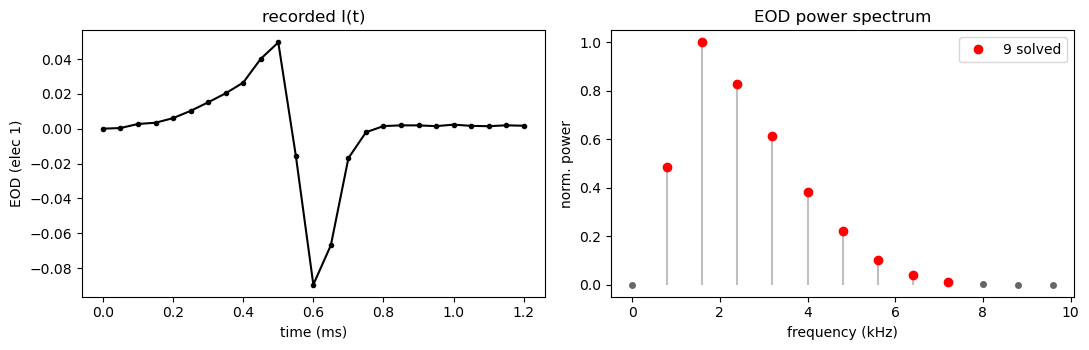

In [102]:
chosen_eod_frame = 25
E, best, dt = load_eod_row(df_eod, row=chosen_eod_frame, fs=20000.0)
I_rec = E[best]
keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt)
print(f"electrode #{best+1} | {n_t} samples @ {1/dt/1e3:.0f} kHz | solving {len(keep)} freqs: "
      f"{np.round(freqs[keep]/1e3,2)} kHz")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(n_t)*dt*1e3, I_rec - I_rec.mean(), 'ko-', ms=3)
ax[0].set_xlabel("time (ms)"); ax[0].set_ylabel(f"EOD (elec {best+1})"); ax[0].set_title("recorded I(t)")
ax[1].vlines(freqs/1e3, 0, Pw/Pw.max(), color='0.75'); ax[1].plot(freqs/1e3, Pw/Pw.max(), 'o', color='0.4', ms=4)
ax[1].plot(freqs[keep]/1e3, (Pw/Pw.max())[keep], 'ro', label=f"{len(keep)} solved")
ax[1].set_xlabel("frequency (kHz)"); ax[1].set_ylabel("norm. power"); ax[1].set_title("EOD power spectrum"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Time-domain field, solving only the kept frequencies

`phi_hat(ω) = Ihat(ω) · psi(ω)`, where `psi` is the transfer function (unit source). Inverse-FFT -> `φ(t)` at the probe cells.

Resistive shortcut: if `eps=0` everywhere, `gamma` is real and ω-independent, so we solve **once** and scale by `I(t)` (no frequency loop).

In [103]:
# def solve_eod_field(I_rec, dt, masks, N, source_fish, probes, power_keep=0.999, **mat):
#     """phi(t) at probe cells. Fish `source_fish` emits (its body skipped from gamma);
#        the OTHER fish are two-layer boundaries. Loops only over kept EOD frequencies."""
#     h = 1.0/(N-1)
#     tail, head = fish_axis_from_mask(masks[source_fish])
#     pos, cur = multipole_sources(tail, head, n=101, I0=1.0)
#     b_unit = build_multipole_b(pos, cur, h, N)

#     sigma, eps, layers = material_layers(masks, N, skip=source_fish, **mat)   # geometry once
#     resistive = not np.any(eps != 0.0)

#     keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt, power_keep)
#     pidx = [idx(i, j, N) for i, j in probes]

#     if resistive:                                          # one solve, scale by I(t)
#         A = build_A_gamma(sigma.astype(complex), N)
#         psi = solve_potential(A, b_unit)[pidx].real
#         phi_t = np.outer(I_rec - I_rec.mean(), psi)
#     else:                                                  # frequency loop
#         phi_hat = np.zeros((len(Ihat), len(probes)), complex)
#         for k in keep:
#             A = build_A_gamma(sigma + 1j*om[k]*eps, N)
#             phi_hat[k] = Ihat[k] * solve_potential(A, b_unit)[pidx]
#         phi_t = np.fft.irfft(phi_hat, n=n_t, axis=0)
#     return phi_t, dict(pos=pos, cur=cur, sigma=sigma, eps=eps, layers=layers,
#                        keep=keep, freqs=freqs, Pw=Pw, n_t=n_t)

# def solve_eod_field(I_rec, dt, masks, N, source_fish, probes, power_keep=0.999,
#                     delta_h=0.3, **mat):
#     """phi(t) at probe cells. Fish `source_fish` emits (transparent to water: skipped from
#        the material fields); the OTHER fish are shell bodies (water|skin|interior) whose
#        interfaces are placed at the ACTUAL boundary crossings (theta), skin resolved sub-cell
#        via delta_h. Loops only over kept EOD frequencies."""
#     h = 1.0/(N-1)
#     tail, head = fish_axis_from_mask(masks[source_fish])
#     pos, cur = multipole_sources(tail, head, n=100, I0=1.0)          # n=100 -> 101 points total
#     b_unit = build_multipole_b(pos, cur, h, N)

#     # geometry once: outer boundary level-set (source fish skipped -> transparent to water)
#     occ = occupancy_field(masks, N, skip=source_fish)
#     resistive = (mat['eps_water'] == 0.0 and mat['eps_skin'] == 0.0 and mat['eps_interior'] == 0.0)

#     keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt, power_keep)
#     pidx = [idx(i, j, N) for i, j in probes]

#     def gammas(omega):                                              # complex admittivity per material
#         gw = mat['sigma_water']    + 1j*omega*mat['eps_water']
#         gs = mat['sigma_skin']     + 1j*omega*mat['eps_skin']
#         gi = mat['sigma_interior'] + 1j*omega*mat['eps_interior']
#         return gw, gs, gi

#     if resistive:                                                   # one solve, scale by I(t)
#         gw, gs, gi = gammas(0.0)
#         A = build_A_shell(occ, N, delta_h, gw, gs, gi)
#         psi = solve_potential(A, b_unit)[pidx].real
#         phi_t = np.outer(I_rec - I_rec.mean(), psi)
#     else:                                                           # frequency loop
#         phi_hat = np.zeros((len(Ihat), len(probes)), complex)
#         for k in keep:
#             gw, gs, gi = gammas(om[k])
#             A = build_A_shell(occ, N, delta_h, gw, gs, gi)
#             phi_hat[k] = Ihat[k] * solve_potential(A, b_unit)[pidx]
#         phi_t = np.fft.irfft(phi_hat, n=n_t, axis=0)

#     return phi_t, dict(pos=pos, cur=cur, occ=occ, keep=keep, freqs=freqs, Pw=Pw, n_t=n_t)

def solve_eod_field(I_rec, dt, masks, N, n_fish, source_fish, probes, power_keep=0.999,
                    delta_h=0.3, **mat):
    """phi(t) at probe cells. Fish `source_fish` emits (transparent to water: skipped from
       the material fields); the OTHER fish are shell bodies (water|skin|interior) whose
       interfaces are placed at the ACTUAL boundary crossings (theta), skin resolved sub-cell
       via delta_h. Loops only over kept EOD frequencies."""
    h = 1.0/(N-1)
    # tail, head = fish_axis_from_mask(masks[source_fish])
    # pos, cur = multipole_sources(tail, head, n=100, I0=1.0)          # n=100 -> 101 points total
    midline = fish_midline_from_mask(fish_mask[source_fish])          # curved centerline
    pos, cur = multipole_sources(midline, n=n_fish, I0=1.0)   # 101 points along the curve
    b_unit = build_multipole_b(pos, cur, h, N)

    # geometry once: outer boundary level-set (source fish skipped -> transparent to water)
    occ = occupancy_field(masks, N, skip=source_fish)
    resistive = (mat['eps_water'] == 0.0 and mat['eps_skin'] == 0.0 and mat['eps_interior'] == 0.0)

    keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt, power_keep)
    pidx = [idx(i, j, N) for i, j in probes]

    def gammas(omega):                                              # complex admittivity per material
        gw = mat['sigma_water']    + 1j*omega*mat['eps_water']
        gs = mat['sigma_skin']     + 1j*omega*mat['eps_skin']
        gi = mat['sigma_interior'] + 1j*omega*mat['eps_interior']
        return gw, gs, gi

    if resistive:                                                   # one solve, scale by I(t)
        gw, gs, gi = gammas(0.0)
        A = build_A_shell(occ, N, delta_h, gw, gs, gi)
        psi = solve_potential(A, b_unit)[pidx].real
        phi_t = np.outer(I_rec - I_rec.mean(), psi)
    else:                                                           # frequency loop
        phi_hat = np.zeros((len(Ihat), len(probes)), complex)
        for k in keep:
            gw, gs, gi = gammas(om[k])
            A = build_A_shell(occ, N, delta_h, gw, gs, gi)
            phi_hat[k] = Ihat[k] * solve_potential(A, b_unit)[pidx]
        phi_t = np.fft.irfft(phi_hat, n=n_t, axis=0)

    return phi_t, dict(pos=pos, cur=cur, occ=occ, keep=keep, freqs=freqs, Pw=Pw, n_t=n_t)

## 7. Per-fish solve: each of the 4 fish as source, others as boundaries

Field snapshot at the dominant EOD frequency, with two-layer bodies outlined (source = dashed yellow, others: interior solid / skin dotted).

In [104]:
# peaks of the ORIGINAL EOD waveform (use I(t) as fed to the solve = detrended)
pos_peak = I_rec[I_rec > 0].max() if np.any(I_rec > 0) else np.nan     # positive peak
neg_peak = I_rec[I_rec < 0].min() if np.any(I_rec < 0) else np.nan     # negative trough (most negative)

def pct_of_peak(val):
    if val > 0:   return f"+{100*val/pos_peak:.0f}% of peak"
    if val < 0:   return f"-{100*val/neg_peak:.0f}% of trough"   # val<0, neg_peak<0 -> ratio>0
    return "0% (zero crossing)"

## 9. Time-resolved field & perturbation over the first half of the EOD

For a chosen source fish, reconstruct the **full-grid** potential over time — `φ(x,y,t)` **with** the other fish (two-layer bodies) and **without** them (uniform water) — then plot, for each timepoint in the first half of the EOD, the **E-field** (left) and the **perturbation** `Δφ = φ_with − φ_without` (right). Because the skin is capacitive, `Δφ` changes *shape* across the EOD, not just amplitude.

source fish 0: 12 frames, |phi|<0.00138, |dphi|<1.11e-05


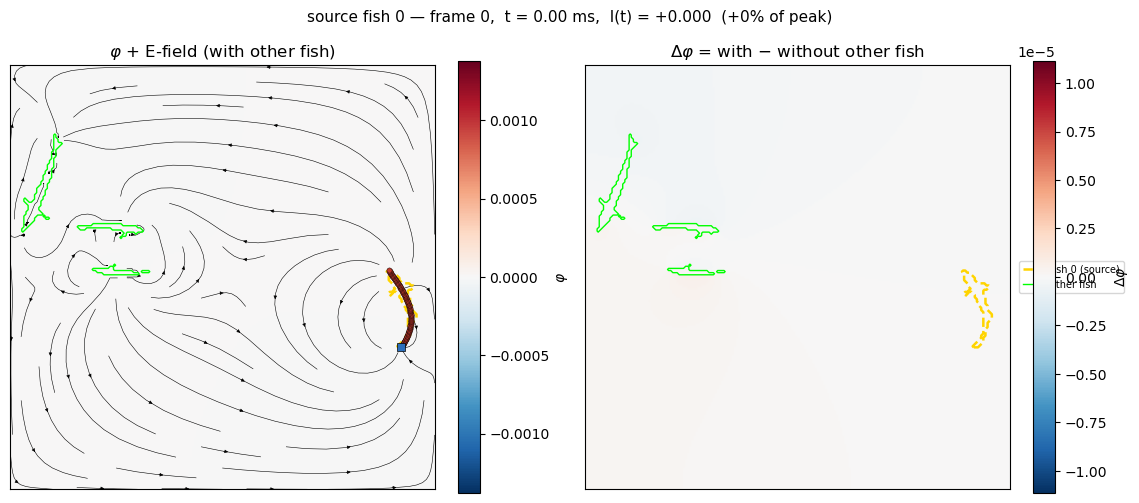

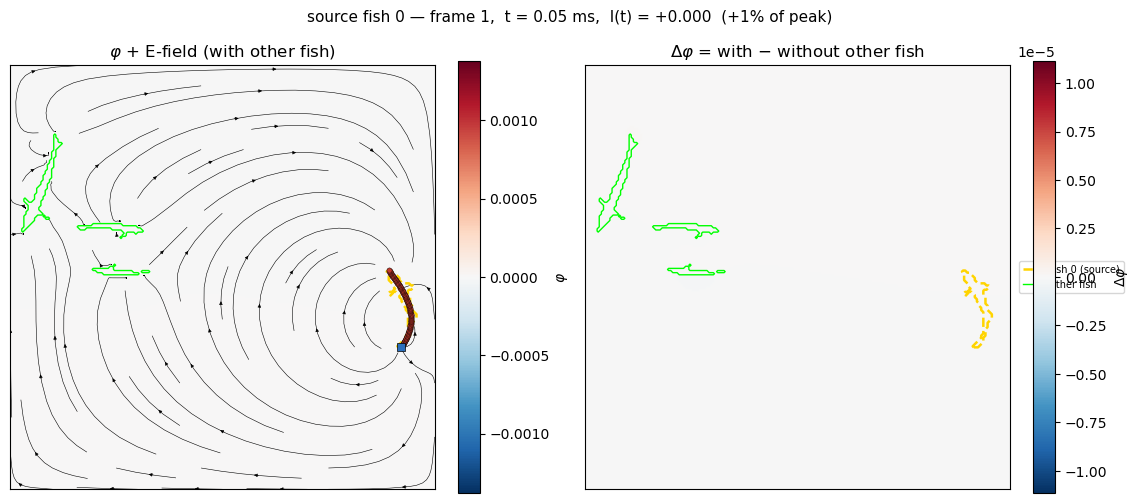

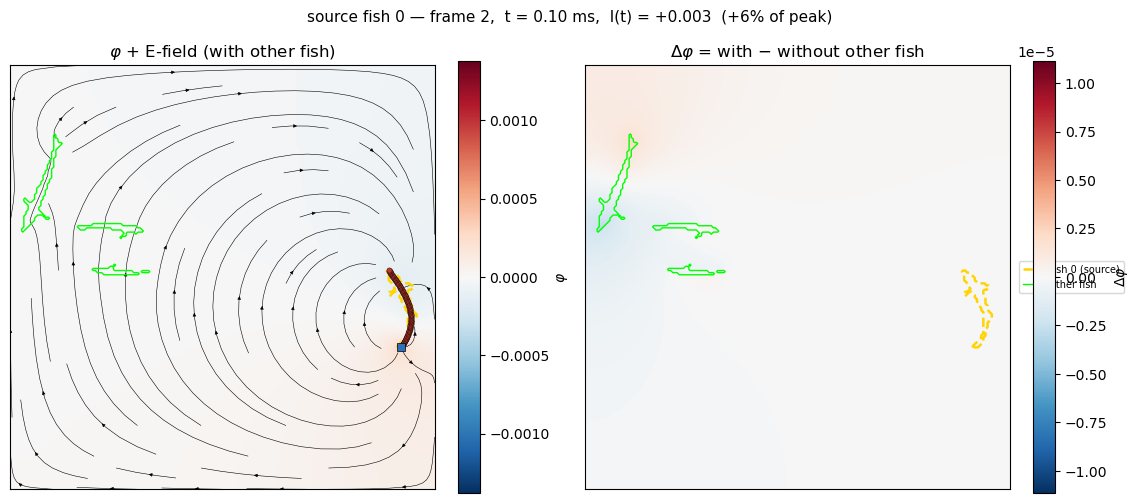

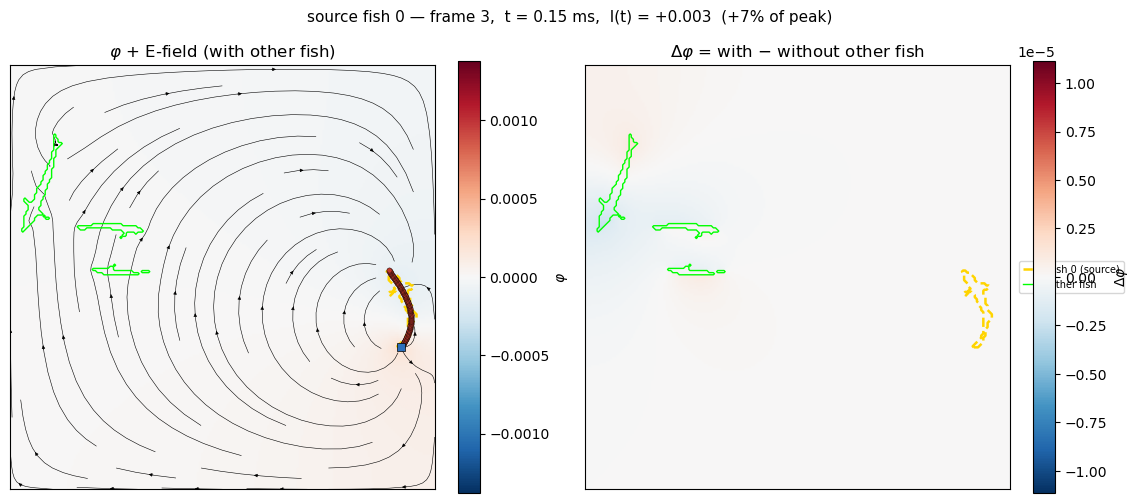

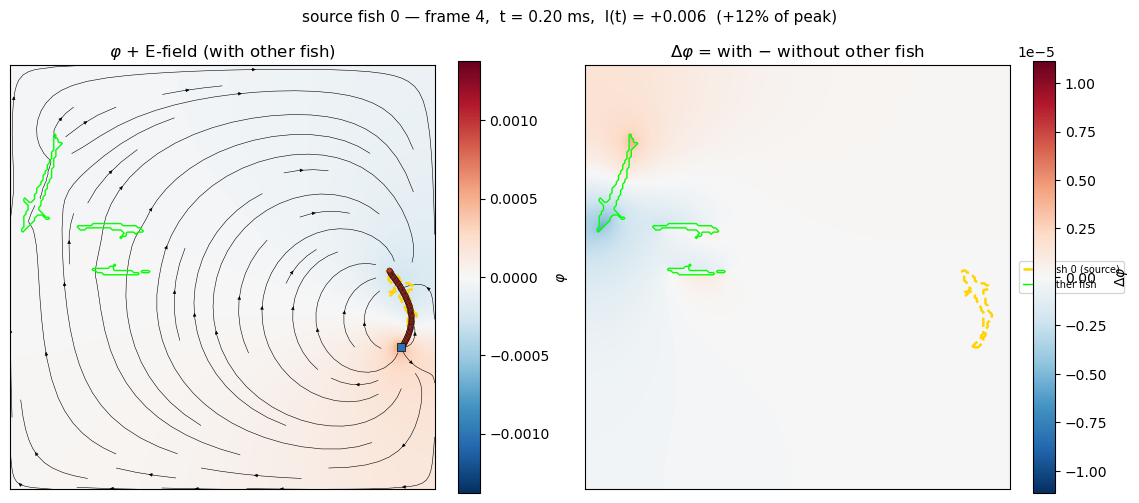

In [105]:
source_fish = 0                     # <- change, or wrap this whole cell in `for source_fish in range(n_fish):`
delta_h = 0.5                       # skin thickness in CELL units (sub-cell shell)

h = 1.0/(N-1)

midline = fish_midline_from_mask(fish_mask[source_fish])          # curved centerline
positions, currents = multipole_sources(midline, n=100, I0=1.0)   # 101 points along the curve
b_unit = build_multipole_b(positions, currents, h, N)

# electrode_locations_file = 'data/electrodes_signed_px_coord_2024-02-13.csv'
# pairs = load_electrode_pairs(electrode_locations_file)   # -> [(pair_id, pos_plus, pos_minus), ...] in [0,1]
# cmap = plt.cm.tab10

# outer-boundary level-set; source fish skipped -> transparent to water
occ_with = occupancy_field(fish_mask, N, skip=source_fish)

def _gammas(omega):                 # complex admittivity per material at this frequency
    gw = MAT['sigma_water']    + 1j*omega*MAT['eps_water']
    gs = MAT['sigma_skin']     + 1j*omega*MAT['eps_skin']
    gi = MAT['sigma_interior'] + 1j*omega*MAT['eps_interior']
    return gw, gs, gi

# WITH other fish: shell transfer function per kept frequency (full grid)
psi_fish = np.zeros((len(Ihat), N*N), complex)
psi_water = np.zeros((len(Ihat), N*N), complex)
for k in keep:
    gw, gs, gi = _gammas(om[k])
    psi_fish[k] = solve_potential(build_A_shell(occ_with, N, delta_h, gw, gs, gi), b_unit)
    psi_water[k] = solve_potential(build_A_shell(occ_with, N, delta_h, gw, gw, gw), b_unit) # same water value for all

# --- reconstruct time-domain fields on the grid ---
# phi_water_t = np.outer(It, psi_water)                        # (n_t, N*N) resistive scaling
# phi_fish_t  = np.fft.irfft(Ihat[:, None] * psi_fish, n=n_t, axis=0)
phi_water_t = np.fft.irfft(Ihat[:, None] * psi_water, n=n_t, axis=0)
phi_fish_t  = np.fft.irfft(Ihat[:, None] * psi_fish, n=n_t, axis=0)
dphi_t = phi_fish_t - phi_water_t                            # perturbation from the OTHER fish

# --- shared colour scales across the plotted (first-half) frames ---
half = n_t // 2
vP = np.percentile(np.abs(phi_fish_t[:half]), 99.5)
vD = np.percentile(np.abs(dphi_t[:half]),     99.0)
print(f"source fish {source_fish}: {half} frames, |phi|<{vP:.3g}, |dphi|<{vD:.3g}")

g = np.linspace(0, 1, N)
srcp, snkp = currents > 0, currents < 0

def _outline(ax):
    for f, m in enumerate(fish_mask):
        if not m.any(): continue
        is_src = (f == source_fish)
        ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5], zorder=4,
                   colors=["#FFD400" if is_src else "lime"],
                   linewidths=1.8 if is_src else 1.0,
                   linestyles="--" if is_src else "-")

for ti in range(5):
    phi  = to_grid(phi_fish_t[ti], N)
    dphi = to_grid(dphi_t[ti], N)
    dpx, dpy = np.gradient(phi, h); Ex, Ey = -dpx, -dpy

    fig, ax = plt.subplots(1, 2, figsize=(11.5, 5.2))
    # LEFT: field + streamlines + source multipole  (shared scale vP across ALL left plots)
    im0 = ax[0].imshow(phi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-vP, vmax=vP)
    if np.ptp(phi) > 0:
        ax[0].streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.4, arrowsize=0.5)
    _outline(ax[0])
    ax[0].plot(positions[:,0], positions[:,1], "-", color="0.2", lw=1, zorder=5)
    ax[0].scatter(*positions[srcp].T, c="#C0392B", s=14, ec="k", lw=0.3, zorder=6)
    ax[0].scatter(*positions[snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5, zorder=6)
    fig.colorbar(im0, ax=ax[0], fraction=0.046, label=r"$\varphi$")     # <-- left colorbar added
    ax[0].set_title(r"$\varphi$ + E-field (with other fish)")

    # RIGHT: perturbation dphi = with - without  (shared scale vD across ALL right plots)
    im1 = ax[1].imshow(dphi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-vD, vmax=vD)
    _outline(ax[1])
    ax[1].plot([], [], color="#FFD400", lw=1.8, ls="--", label=f"fish {source_fish} (source)")
    ax[1].plot([], [], color="lime", lw=1.0, label="other fish")
    fig.colorbar(im1, ax=ax[1], fraction=0.046, label=r"$\Delta\varphi$")
    # ax[1].legend(loc="upper right", fontsize=7, framealpha=0.9)
    ax[1].set_title(r"$\Delta\varphi$ = with $-$ without other fish")

    for a in ax:
        a.set_xlim(0,1); a.set_ylim(0,1); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])

    fig.suptitle(f"source fish {source_fish} — frame {ti},  t = {ti*dt*1e3:.2f} ms,  "
                 f"I(t) = {It[ti]:+.3f}  ({pct_of_peak(It[ti])})",
                 fontsize=11)
    
    # for k, (pid, pos_p, pos_m) in enumerate(pairs):
    #     color = cmap(k % 10)
    #     ax[1].scatter(pos_p[0], pos_p[1], marker='o', s=70, c=[color], ec='k', lw=0.6,
    #             zorder=5, label=f"pair {pid}")                     # + electrode = circle
    #     ax[1].scatter(pos_m[0], pos_m[1], marker='x', s=70, c=[color], lw=2.0, zorder=5)  # - electrode = X
    #     ax[1].plot([pos_p[0], pos_m[0]], [pos_p[1], pos_m[1]], color=color, lw=0.8, alpha=0.5, zorder=4)  # connect

    # # legend proxies for the +/- symbol meaning
    # ax[1].scatter([], [], marker='o', s=70, c='0.5', ec='k', label='+ electrode')
    # ax[1].scatter([], [], marker='x', s=70, c='0.5', label='- electrode')
    ax[1].legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=7, ncol=1)

    plt.tight_layout(); plt.show()

# 10. Compare to ground truth EODs



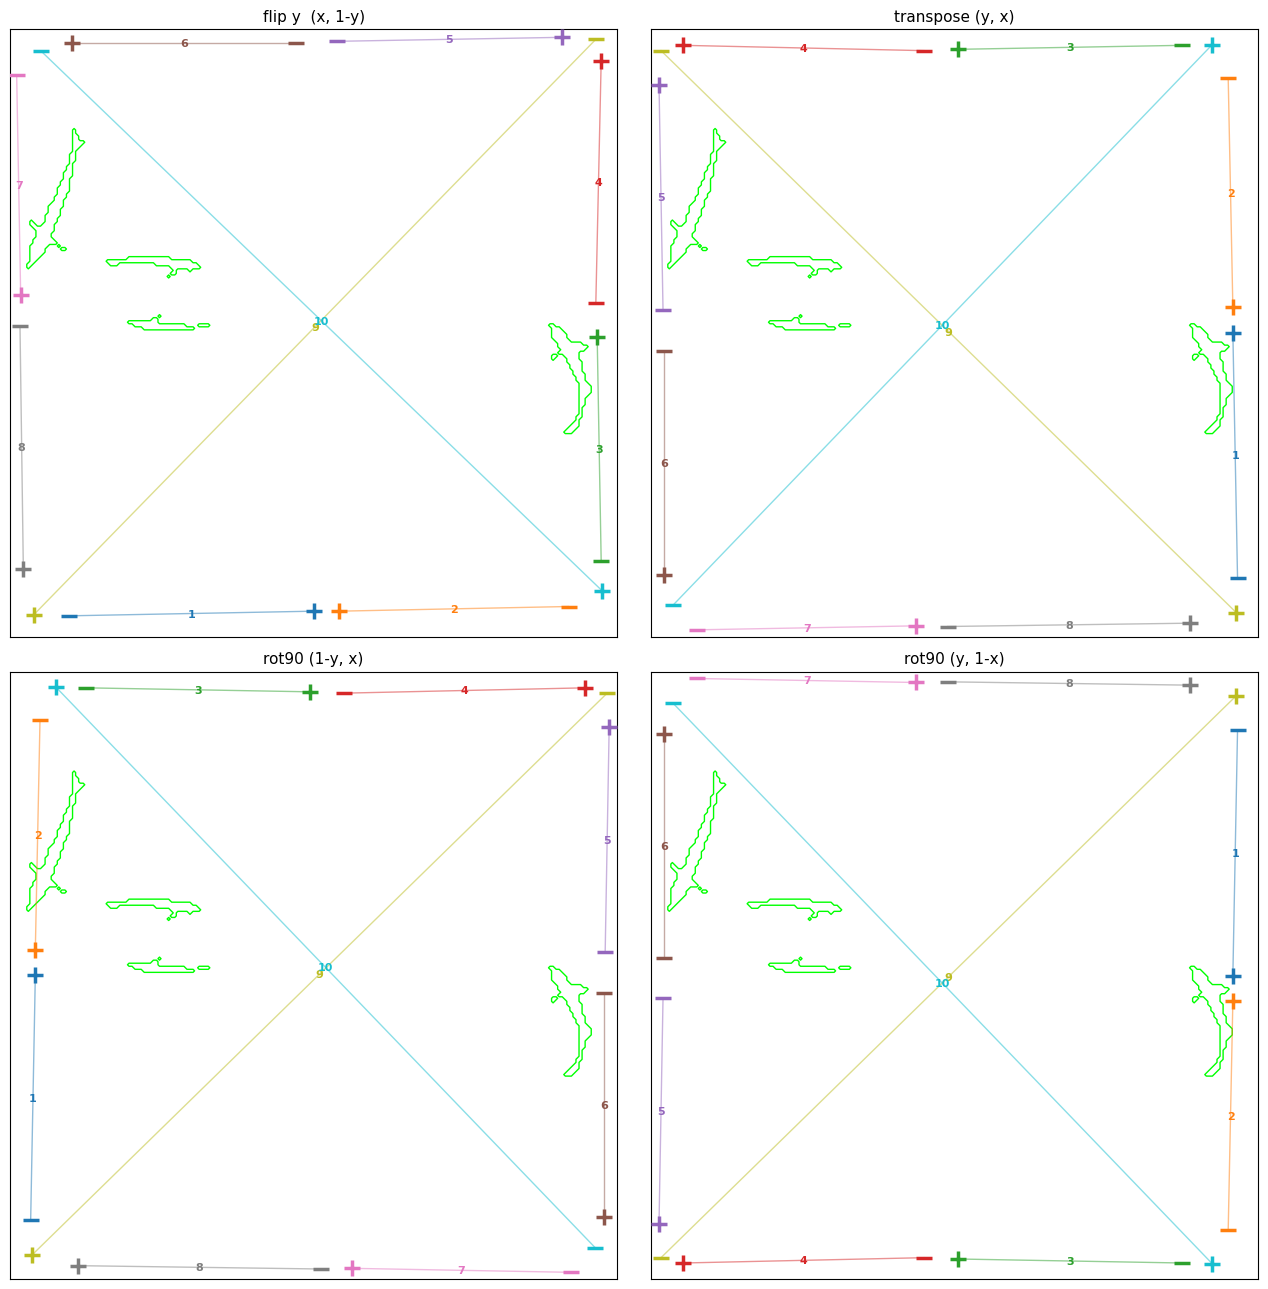

In [106]:
def load_electrode_pairs(csv, N_px=912):
    """CSV electrode coords -> rotated 90° CCW (left) into the mask/tank frame, [0,1].
       Rotation about the center (0.5, 0.5): (x, y) -> (1 - y, x)."""
    df = pd.read_csv(csv)
    def rot90_left(x, y):
        xn, yn = x/(N_px-1), y/(N_px-1)          # pixels -> [0,1]
        # return np.array([xn, yn])          # 90° CCW about center
        # return np.array([1.0 - yn, xn])          # 90° CCW about center
        return np.array([yn, xn]) # rotate to match from video axis to cartesian axis - transpose is the right one
    pairs = []
    for _, r in df.iterrows():
        if str(r['pol1']).strip() == '+':
            (x1, y1), (x2, y2) = (r['x1'], r['y1']), (r['x2'], r['y2'])
        else:
            (x1, y1), (x2, y2) = (r['x2'], r['y2']), (r['x1'], r['y1'])
        pairs.append((int(r['pair']), rot90_left(x1, y1), rot90_left(x2, y2)))
    return pairs

electrode_locations_file = 'data/electrodes_signed_px_coord_2024-02-13.csv'
pairs = load_electrode_pairs(electrode_locations_file, N_px=912)

g = np.linspace(0, 1, N)
raw = pd.read_csv('data/electrodes_signed_px_coord_2024-02-13.csv')
cmap = plt.cm.tab10

transforms = {
    "flip y  (x, 1-y)":  lambda x, y: (x, 1-y),
    "transpose (y, x)":  lambda x, y: (y, x),
    "rot90 (1-y, x)":    lambda x, y: (1-y, x),
    "rot90 (y, 1-x)":    lambda x, y: (y, 1-x),
}

fig, axes = plt.subplots(2, 2, figsize=(13, 13))
for ax, (name, T) in zip(axes.ravel(), transforms.items()):
    # fish outlines
    for f, m in enumerate(fish_mask):
        if m.any():
            ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5], colors='lime', linewidths=1)

    # electrodes: color per pair, marker per polarity
    for k, (_, r) in enumerate(raw.iterrows()):
        color = cmap(k % 10)
        # order the two points by polarity
        if str(r['pol1']).strip() == '+':
            (xp, yp), (xm, ym) = (r['x1'], r['y1']), (r['x2'], r['y2'])
        else:
            (xp, yp), (xm, ym) = (r['x2'], r['y2']), (r['x1'], r['y1'])
        Xp, Yp = T(xp/911, yp/911)                       # + electrode
        Xm, Ym = T(xm/911, ym/911)                       # - electrode
        ax.scatter(Xp, Yp, marker='+', s=140, c=[color], linewidths=2.5, zorder=6)   # +  = plus symbol
        ax.scatter(Xm, Ym, marker='_', s=140, c=[color], linewidths=2.5, zorder=6)   # -  = minus symbol
        ax.plot([Xp, Xm], [Yp, Ym], color=color, lw=1.0, alpha=0.5, zorder=4)        # connect the pair
        # label the pair number at its midpoint
        ax.text((Xp+Xm)/2, (Yp+Ym)/2, str(int(r['pair'])), color=color,
                fontsize=8, fontweight='bold', ha='center', va='center', zorder=7)

    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.set_title(name, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout(); plt.show()



source fish 0: 12 frames, |phi|<0.00138, |dphi|<1.11e-05


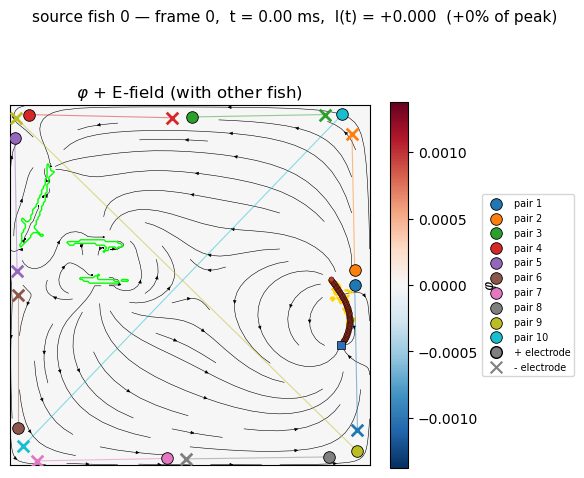

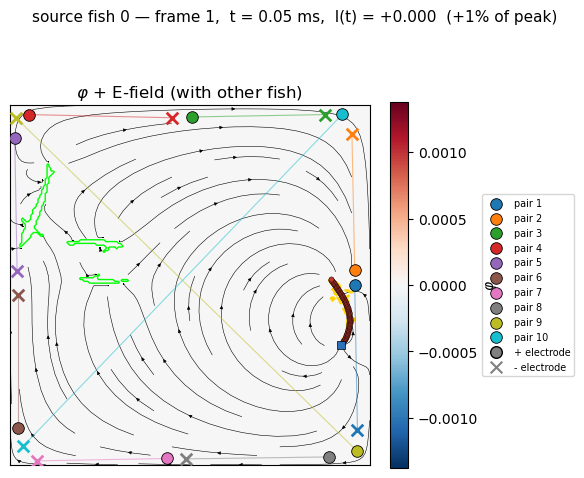

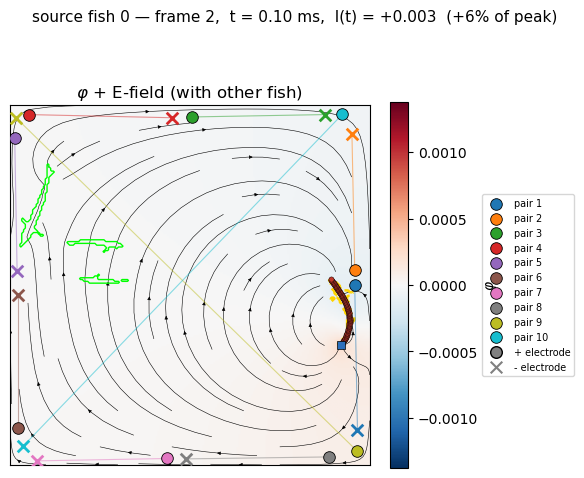

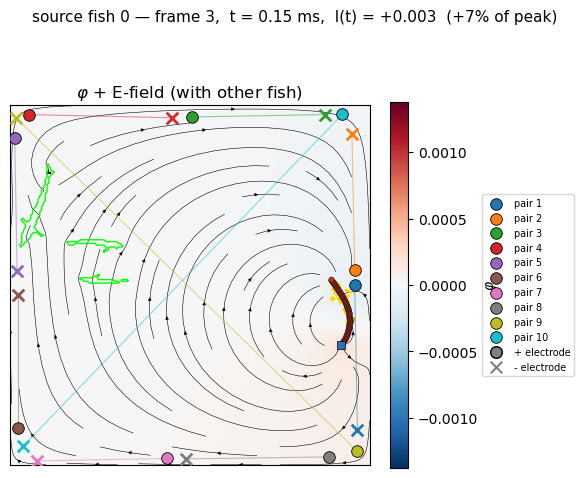

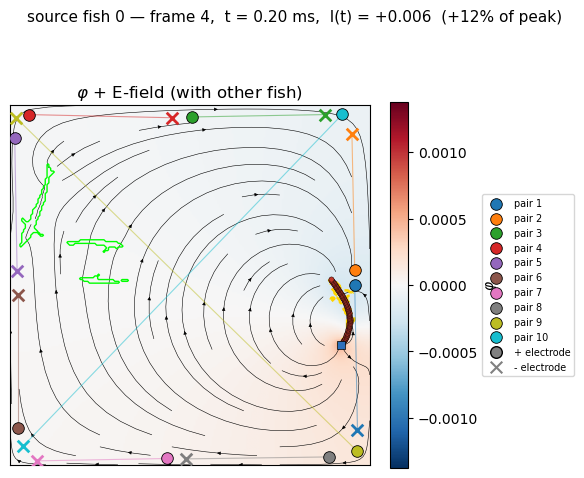

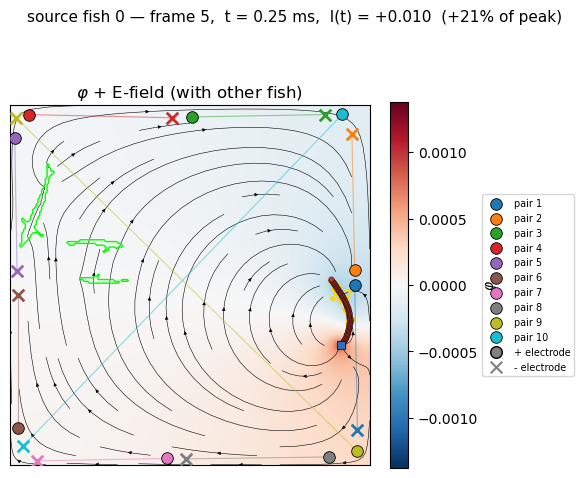

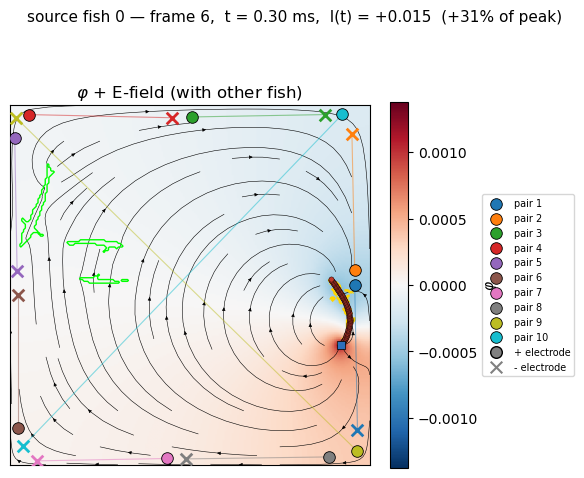

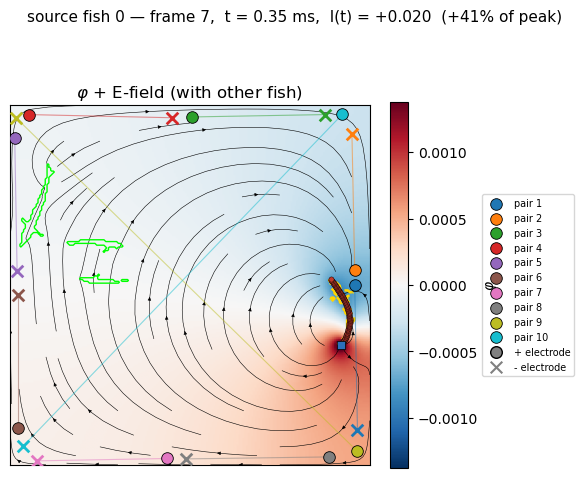

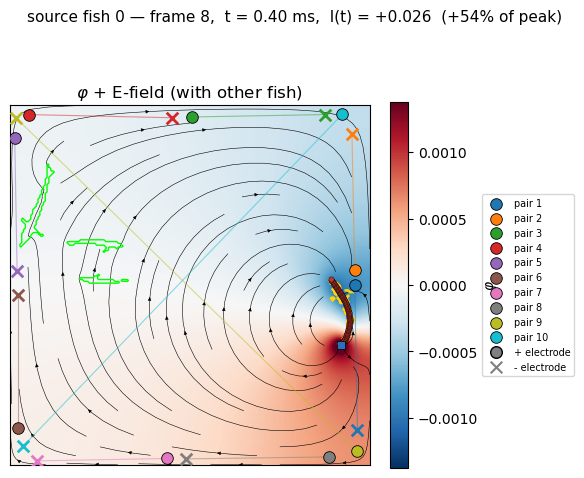

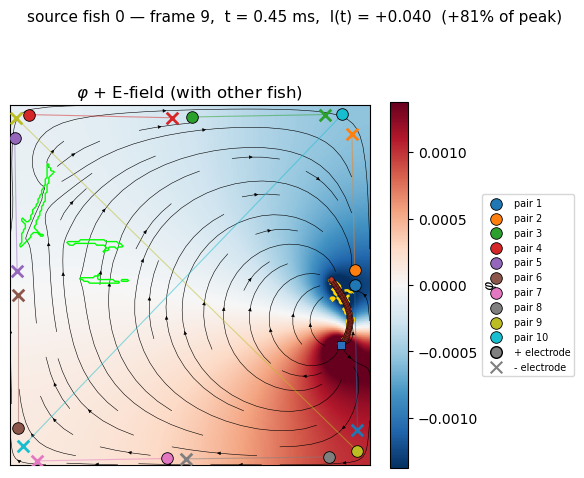

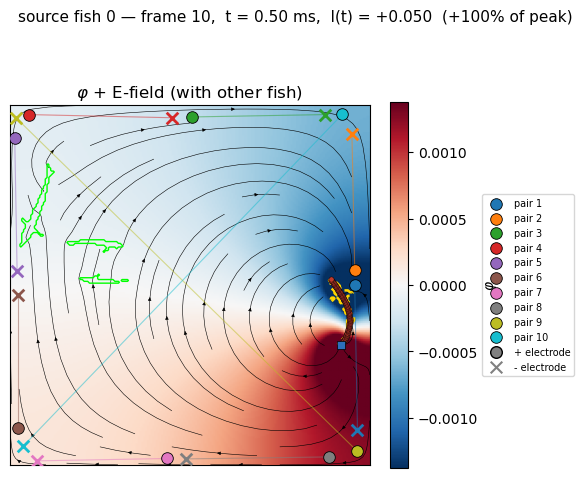

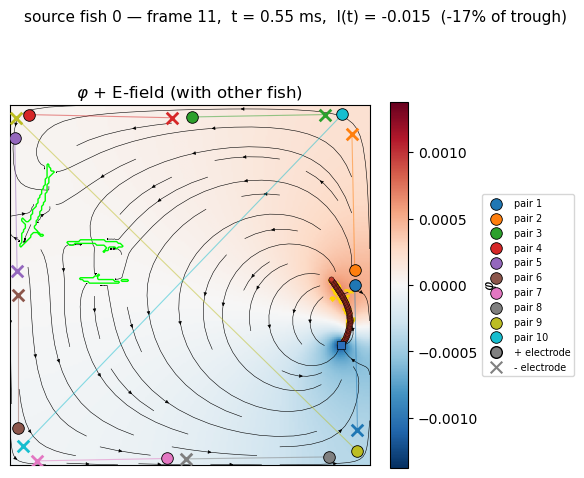

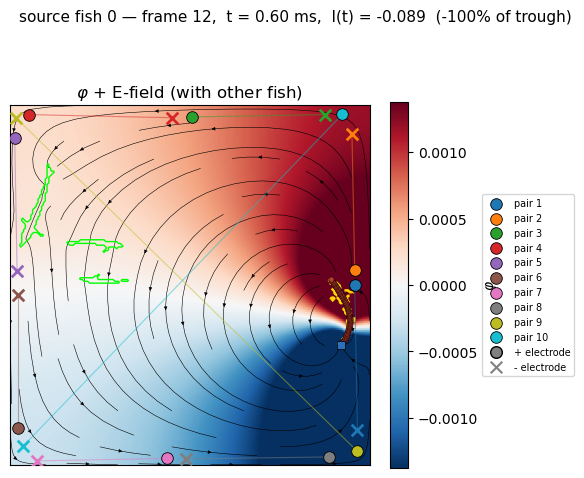

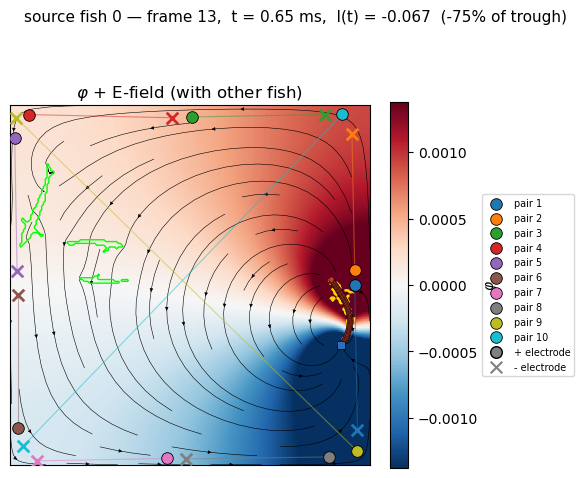

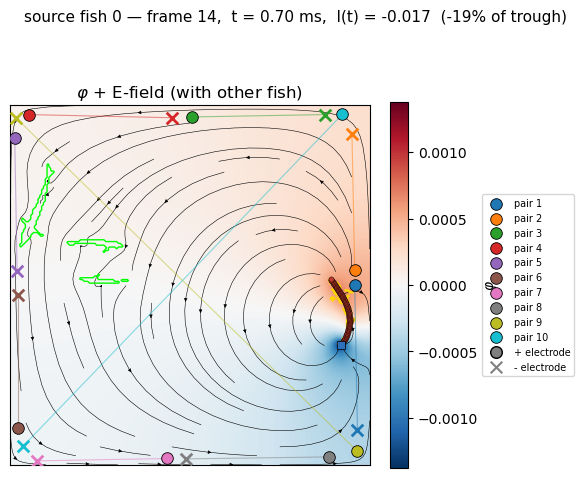

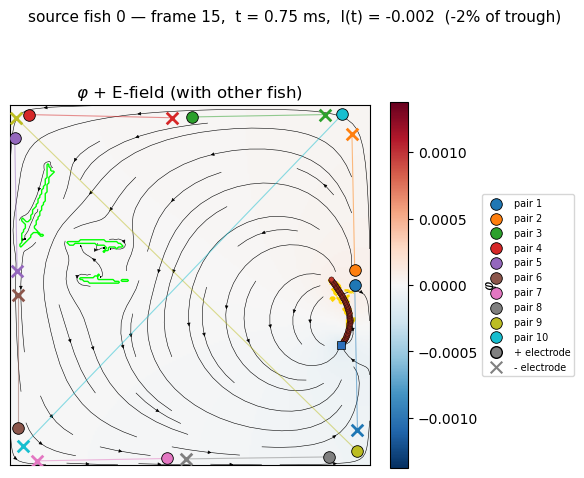

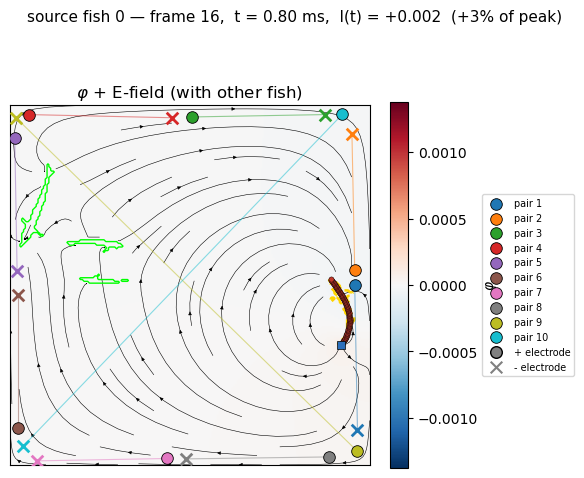

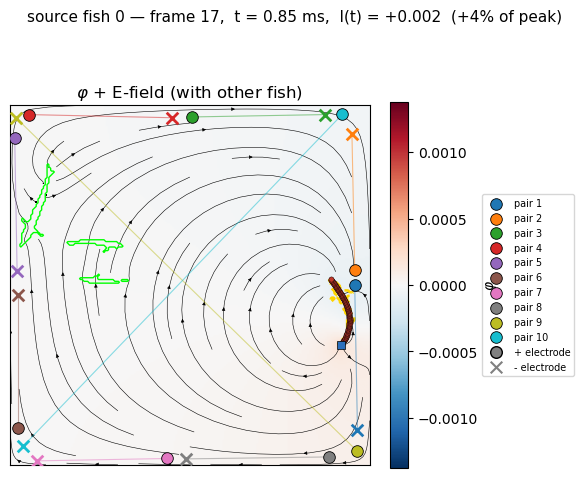

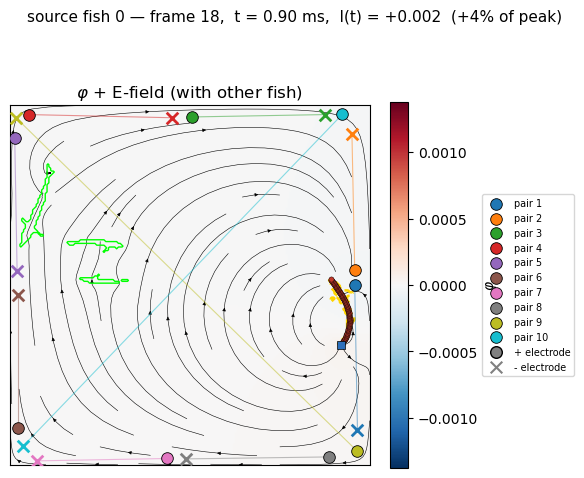

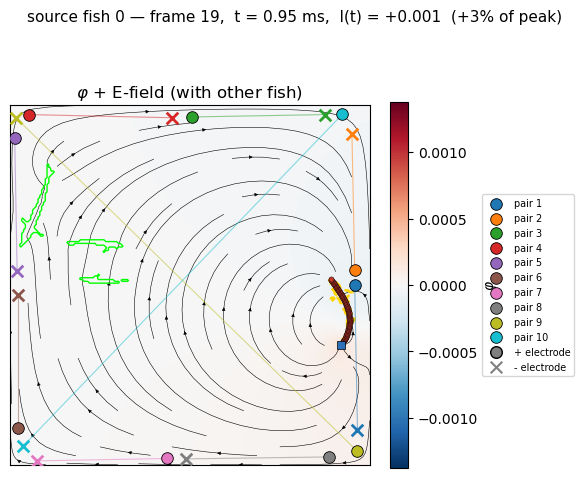

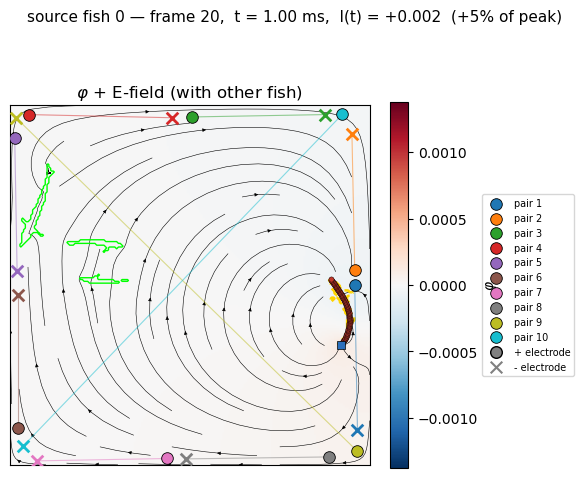

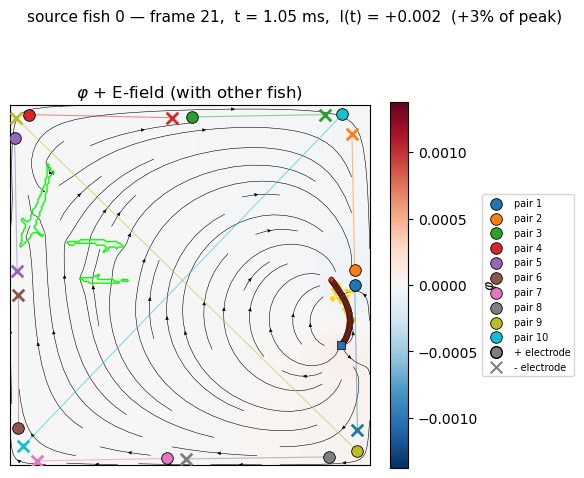

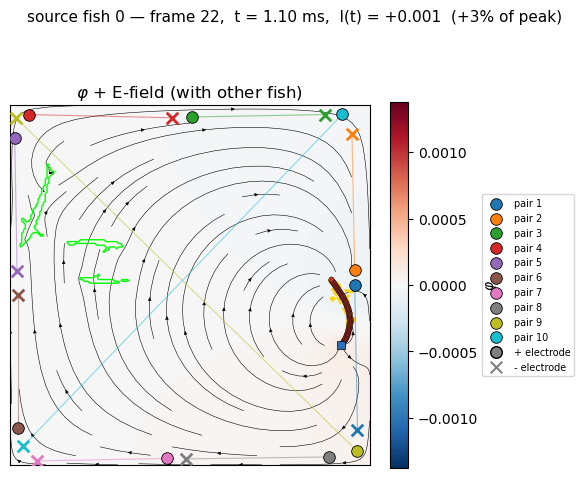

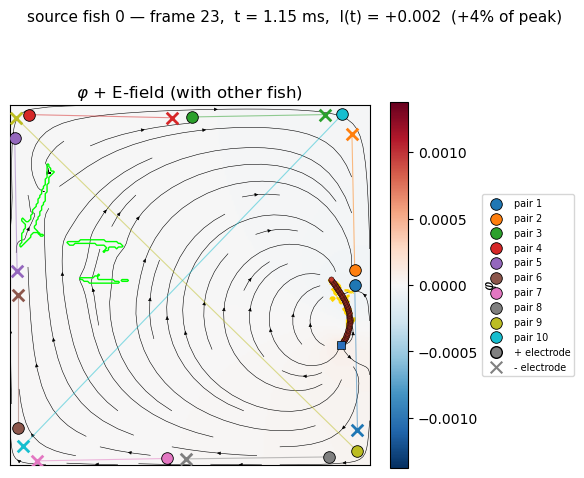

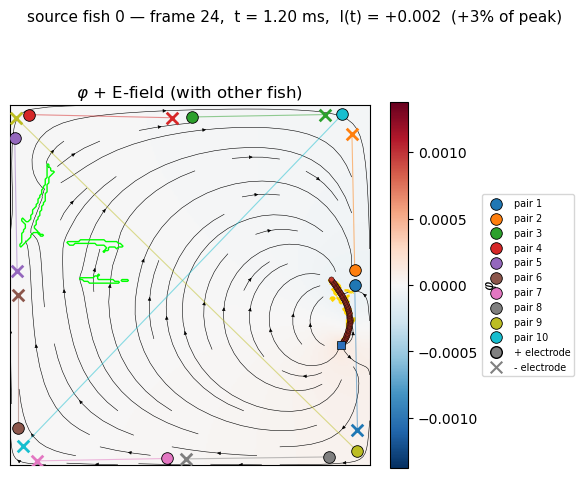

In [115]:
source_fish = 0                     # <- change, or wrap this whole cell in `for source_fish in range(n_fish):`
delta_h = 0.5                       # skin thickness in CELL units (sub-cell shell)

h = 1.0/(N-1)

midline = fish_midline_from_mask(fish_mask[source_fish])          # curved centerline
positions, currents = multipole_sources(midline, n=100, I0=1.0)   # 101 points along the curve
b_unit = build_multipole_b(positions, currents, h, N)

electrode_locations_file = 'data/electrodes_signed_px_coord_2024-02-13.csv'
pairs = load_electrode_pairs(electrode_locations_file)   # -> [(pair_id, pos_plus, pos_minus), ...] in [0,1]
cmap = plt.cm.tab10

# outer-boundary level-set; source fish skipped -> transparent to water
occ_with = occupancy_field(fish_mask, N, skip=source_fish)

def _gammas(omega):                 # complex admittivity per material at this frequency
    gw = MAT['sigma_water']    + 1j*omega*MAT['eps_water']
    gs = MAT['sigma_skin']     + 1j*omega*MAT['eps_skin']
    gi = MAT['sigma_interior'] + 1j*omega*MAT['eps_interior']
    return gw, gs, gi

# WITH other fish: shell transfer function per kept frequency (full grid)
psi_fish = np.zeros((len(Ihat), N*N), complex)
psi_water = np.zeros((len(Ihat), N*N), complex)
for k in keep:
    gw, gs, gi = _gammas(om[k])
    psi_fish[k] = solve_potential(build_A_shell(occ_with, N, delta_h, gw, gs, gi), b_unit)
    psi_water[k] = solve_potential(build_A_shell(occ_with, N, delta_h, gw, gw, gw), b_unit) # same water value for all

# --- reconstruct time-domain fields on the grid ---
It = I_rec - I_rec.mean()
# phi_water_t = np.outer(It, psi_water)                        # (n_t, N*N) resistive scaling
# phi_fish_t  = np.fft.irfft(Ihat[:, None] * psi_fish, n=n_t, axis=0)
phi_water_t = np.fft.irfft(Ihat[:, None] * psi_water, n=n_t, axis=0)
phi_fish_t  = np.fft.irfft(Ihat[:, None] * psi_fish, n=n_t, axis=0)
dphi_t = phi_fish_t - phi_water_t                            # perturbation from the OTHER fish

# --- shared colour scales across the plotted (first-half) frames ---
half = n_t // 2
vP = np.percentile(np.abs(phi_fish_t[:half]), 99.5)
vD = np.percentile(np.abs(dphi_t[:half]),     99.0)
print(f"source fish {source_fish}: {half} frames, |phi|<{vP:.3g}, |dphi|<{vD:.3g}")

g = np.linspace(0, 1, N)
srcp, snkp = currents > 0, currents < 0

def _outline(ax):
    for f, m in enumerate(fish_mask):
        if not m.any(): continue
        is_src = (f == source_fish)
        ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5], zorder=4,
                   colors=["#FFD400" if is_src else "lime"],
                   linewidths=1.8 if is_src else 1.0,
                   linestyles="--" if is_src else "-")

for ti in range(25):
    phi  = to_grid(phi_fish_t[ti], N)
    dphi = to_grid(dphi_t[ti], N)
    dpx, dpy = np.gradient(phi, h); Ex, Ey = -dpx, -dpy

    fig, ax = plt.subplots(figsize=(6, 5.2))
    
    # LEFT: field + streamlines + source multipole  (shared scale vP across ALL left plots)
    im0 = ax.imshow(phi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-vP, vmax=vP)
    if np.ptp(phi) > 0:
        ax.streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.4, arrowsize=0.5)
    _outline(ax)
    ax.plot(positions[:,0], positions[:,1], "-", color="0.2", lw=1, zorder=5)
    ax.scatter(*positions[srcp].T, c="#C0392B", s=14, ec="k", lw=0.3, zorder=6)
    ax.scatter(*positions[snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5, zorder=6)
    fig.colorbar(im0, ax=ax, fraction=0.046, label=r"$\varphi$")     # <-- left colorbar added
    ax.set_title(r"$\varphi$ + E-field (with other fish)")

    ax.set_xlim(0,1); ax.set_ylim(1,0); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

    fig.suptitle(f"source fish {source_fish} — frame {ti},  t = {ti*dt*1e3:.2f} ms,  "
                 f"I(t) = {It[ti]:+.3f}  ({pct_of_peak(It[ti])})",
                 fontsize=11)
    
    for k, (pid, pos_p, pos_m) in enumerate(pairs):
        color = cmap(k % 10)
        ax.scatter(pos_p[0], pos_p[1], marker='o', s=70, c=[color], ec='k', lw=0.6,
                zorder=5, label=f"pair {pid}")                     # + electrode = circle
        ax.scatter(pos_m[0], pos_m[1], marker='x', s=70, c=[color], lw=2.0, zorder=5)  # - electrode = X
        ax.plot([pos_p[0], pos_m[0]], [pos_p[1], pos_m[1]], color=color, lw=0.8, alpha=0.5, zorder=4)  # connect

    # legend proxies for the +/- symbol meaning
    ax.scatter([], [], marker='o', s=70, c='0.5', ec='k', label='+ electrode')
    ax.scatter([], [], marker='x', s=70, c='0.5', label='- electrode')
    ax.legend(loc='center left', bbox_to_anchor=(1.3, 0.5), fontsize=7, ncol=1)

    # ax[0] styling (map)
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

In [112]:
# --- simulated electrode-pair voltages for THIS source fish: V = phi(+) - phi(-) ---
def _gammas(omega):
    gw = MAT['sigma_water']    + 1j*omega*MAT['eps_water']
    gs = MAT['sigma_skin']     + 1j*omega*MAT['eps_skin']
    gi = MAT['sigma_interior'] + 1j*omega*MAT['eps_interior']
    return gw, gs, gi

def sample_phi_t(phi_t, p):
    fi, fj = p[0]/h, p[1]/h
    i, j = int(fi), int(fj); a, c = fi-i, fj-j
    def w(ii, jj): return phi_t[:, idx(min(max(ii,0),N-1), min(max(jj,0),N-1), N)]
    return ((1-a)*(1-c)*w(i,j) + a*(1-c)*w(i+1,j) + (1-a)*c*w(i,j+1) + a*c*w(i+1,j+1))

t_ms = np.arange(n_t)*dt*1e3
V_sim_pairs = {pid: sample_phi_t(phi_fish_t, pp) - sample_phi_t(phi_fish_t, pm)
               for pid, pp, pm in pairs}

def rec_trace(pid, eod_chosen_frame):
    et = [f'electrode_{pid}_time_{i}' for i in range(1, 26)]
    vr = np.array(df_eod.loc[eod_chosen_frame, et], dtype=float)
    return vr - vr.mean()

V_rec_pairs = {pid: rec_trace(pid) for pid, _, _ in pairs}

# --- normalize each set by its own global peak (max |value| across ALL electrodes) -> peak = 1 ---
sim_peak = max(np.abs(v).max() for v in V_sim_pairs.values())
rec_peak = max(np.abs(v).max() for v in V_rec_pairs.values())

V_sim_pairs = {pid: v / sim_peak for pid, v in V_sim_pairs.items()}   # max sim value now 1
V_rec_pairs = {pid: v / rec_peak for pid, v in V_rec_pairs.items()}   # max rec value now 1

TypeError: rec_trace() missing 1 required positional argument: 'eod_chosen_frame'

stored fish 0: 10 pairs (sim_peak=0.00529)


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_54261/3247541818.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,1,0.96])


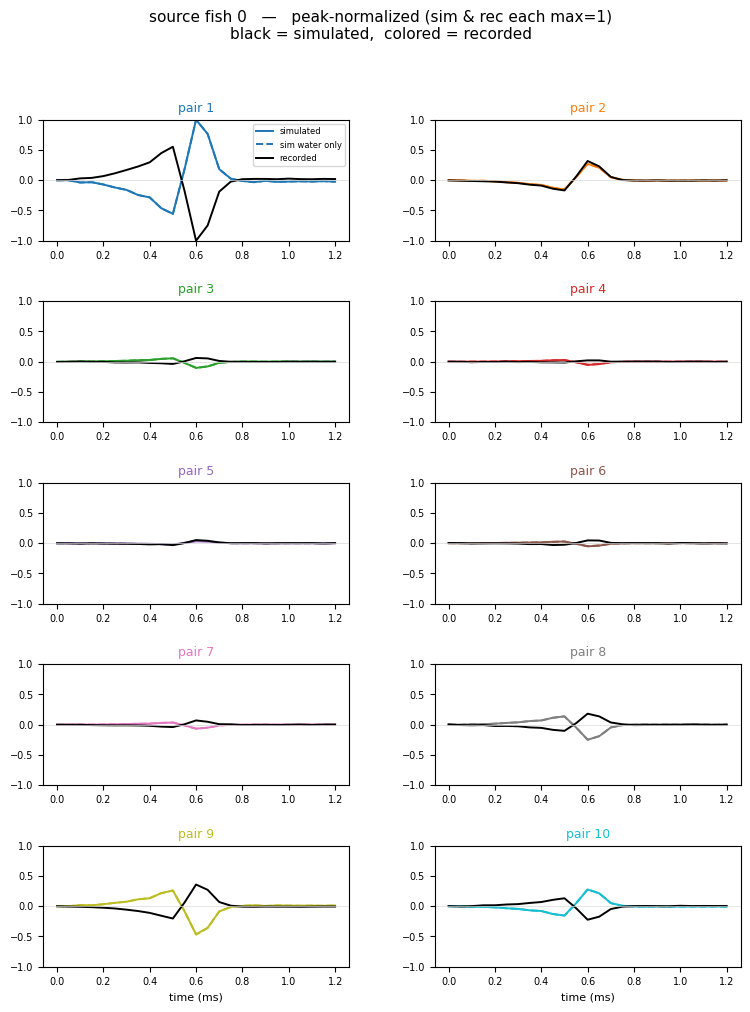

stored fish 1: 10 pairs (sim_peak=0.00795)


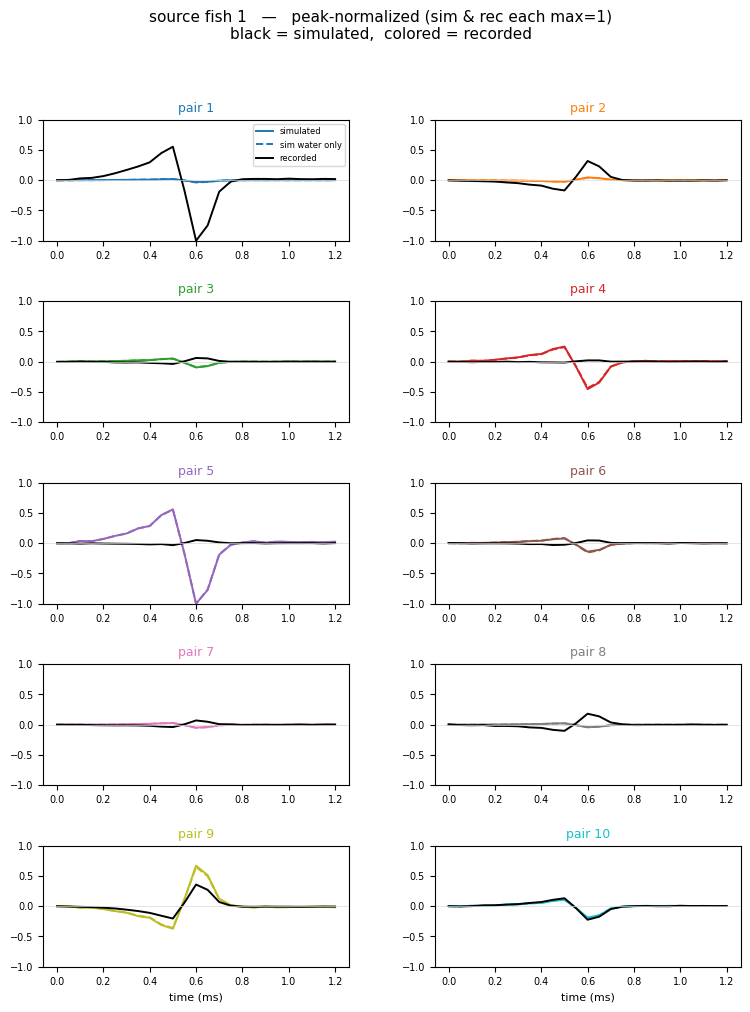

stored fish 2: 10 pairs (sim_peak=0.000539)


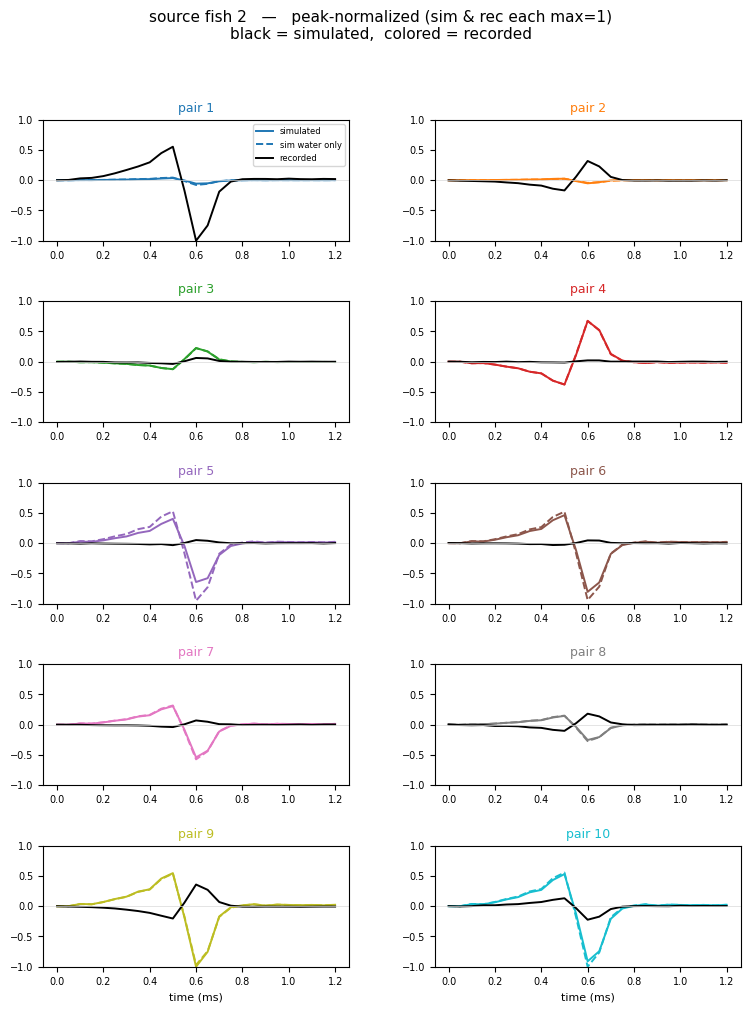

stored fish 3: 10 pairs (sim_peak=0.00101)


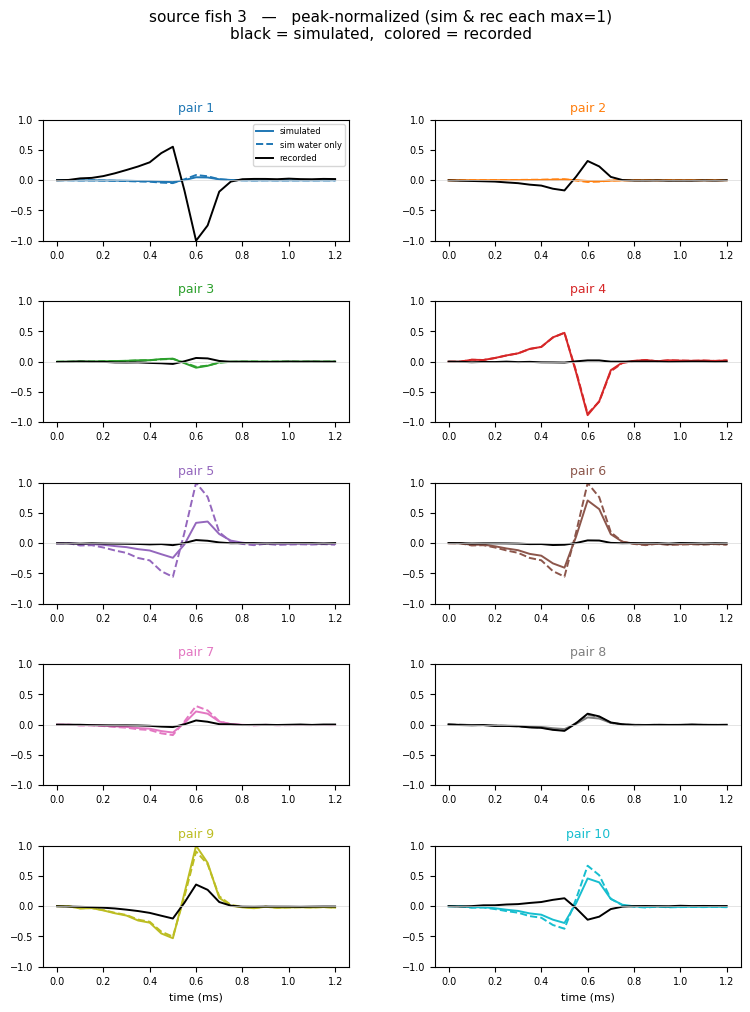

In [113]:
from matplotlib.gridspec import GridSpec

delta_h = 0.5
h = 1.0/(N-1)
cmap = plt.cm.tab10
pairs = load_electrode_pairs(electrode_locations_file)
t_ms = np.arange(n_t)*dt*1e3

# recorded voltages + peak normalization (same for every fish -> compute once)
V_rec_pairs = {pid: rec_trace(pid, chosen_eod_frame) for pid, _, _ in pairs}
rec_peak = max(np.abs(v).max() for v in V_rec_pairs.values())
V_rec_pairs = {pid: v / rec_peak for pid, v in V_rec_pairs.items()}      # max recorded = 1

# --- storage: per-fish results ---
V_sim_all   = {}          # V_sim_all[sf][pid] = normalized simulated trace
phi_all     = {}          # optional: keep each fish's full field if you need it later

V_sim_water_all = {}

# --- loop over each fish as source ---
for source_fish in range(4):
    # field for this source fish (with the others present)
    midline = fish_midline_from_mask(fish_mask[source_fish])
    positions, currents = multipole_sources(midline, n=100, I0=1.0)
    b_unit = build_multipole_b(positions, currents, h, N)
    occ = occupancy_field(fish_mask, N, skip=source_fish)

    psi_fish = np.zeros((len(Ihat), N*N), complex)
    psi_water = np.zeros((len(Ihat), N*N), complex)
    for k in keep:
        gw, gs, gi = _gammas(om[k])
        psi_fish[k] = solve_potential(build_A_shell(occ, N, delta_h, gw, gs, gi), b_unit)
        psi_water[k] = solve_potential(build_A_shell(occ_with, N, delta_h, gw, gw, gw), b_unit) # same water value for all
    phi_fish_t = np.fft.irfft(Ihat[:, None] * psi_fish, n=n_t, axis=0)
    phi_water_t = np.fft.irfft(Ihat[:, None] * psi_water, n=n_t, axis=0)

    # simulated pair voltages, peak-normalized (max across all electrodes = 1)
    V_sim_pairs = {pid: sample_phi_t(phi_fish_t, pp) - sample_phi_t(phi_fish_t, pm)
                   for pid, pp, pm in pairs}
    sim_peak = max(np.abs(v).max() for v in V_sim_pairs.values())
    V_sim_pairs = {pid: v / sim_peak for pid, v in V_sim_pairs.items()}

    V_sim_pairs_water = {pid: sample_phi_t(phi_water_t, pp) - sample_phi_t(phi_water_t, pm)
                   for pid, pp, pm in pairs}
    sim_peak_water = max(np.abs(v).max() for v in V_sim_pairs_water.values())
    V_sim_pairs_water = {pid: v / sim_peak_water for pid, v in V_sim_pairs_water.items()}

    # --- store this fish's results ---
    V_sim_all[source_fish] = V_sim_pairs
    V_sim_water_all[source_fish] = V_sim_pairs_water
    phi_all[source_fish]   = phi_fish_t        # remove this line if memory is tight

    print(f"stored fish {source_fish}: {len(V_sim_pairs)} pairs (sim_peak={sim_peak:.3g})")

    # 5x2 grid of tiny plots
    fig = plt.figure(figsize=(9, 11))
    gs = GridSpec(5, 2, figure=fig, hspace=0.5, wspace=0.28)
    for k, (pid, _, _) in enumerate(pairs):
        ax = fig.add_subplot(gs[k]); color = cmap(k % 10)
        ax.plot(t_ms, V_sim_pairs[pid], color=color, lw=1.4, label='simulated')
        ax.plot(t_ms, V_sim_pairs_water[pid], ls='--', color=color, lw=1.4, label='sim water only')
        ax.plot(t_ms, V_rec_pairs[pid], color='black', lw=1.4, label='recorded')
        ax.axhline(0, color='0.85', lw=0.5)
        ax.set_ylim(-1,1)                                  # shared scale
        ax.set_title(f"pair {pid}", fontsize=9, color=color)
        ax.tick_params(labelsize=7)
        if k >= len(pairs)-2: ax.set_xlabel("time (ms)", fontsize=8)
        if k == 0: ax.legend(fontsize=6)
    fig.suptitle(f"source fish {source_fish}   —   peak-normalized (sim & rec each max=1)\n"
                 "black = simulated,  colored = recorded", fontsize=11)
    plt.tight_layout(rect=[0,0,1,0.96])
    fig.savefig(f"eod_electrodes_fish{source_fish}.png", dpi=130, bbox_inches="tight")   # save per fish
    plt.show()
    plt.close(fig)

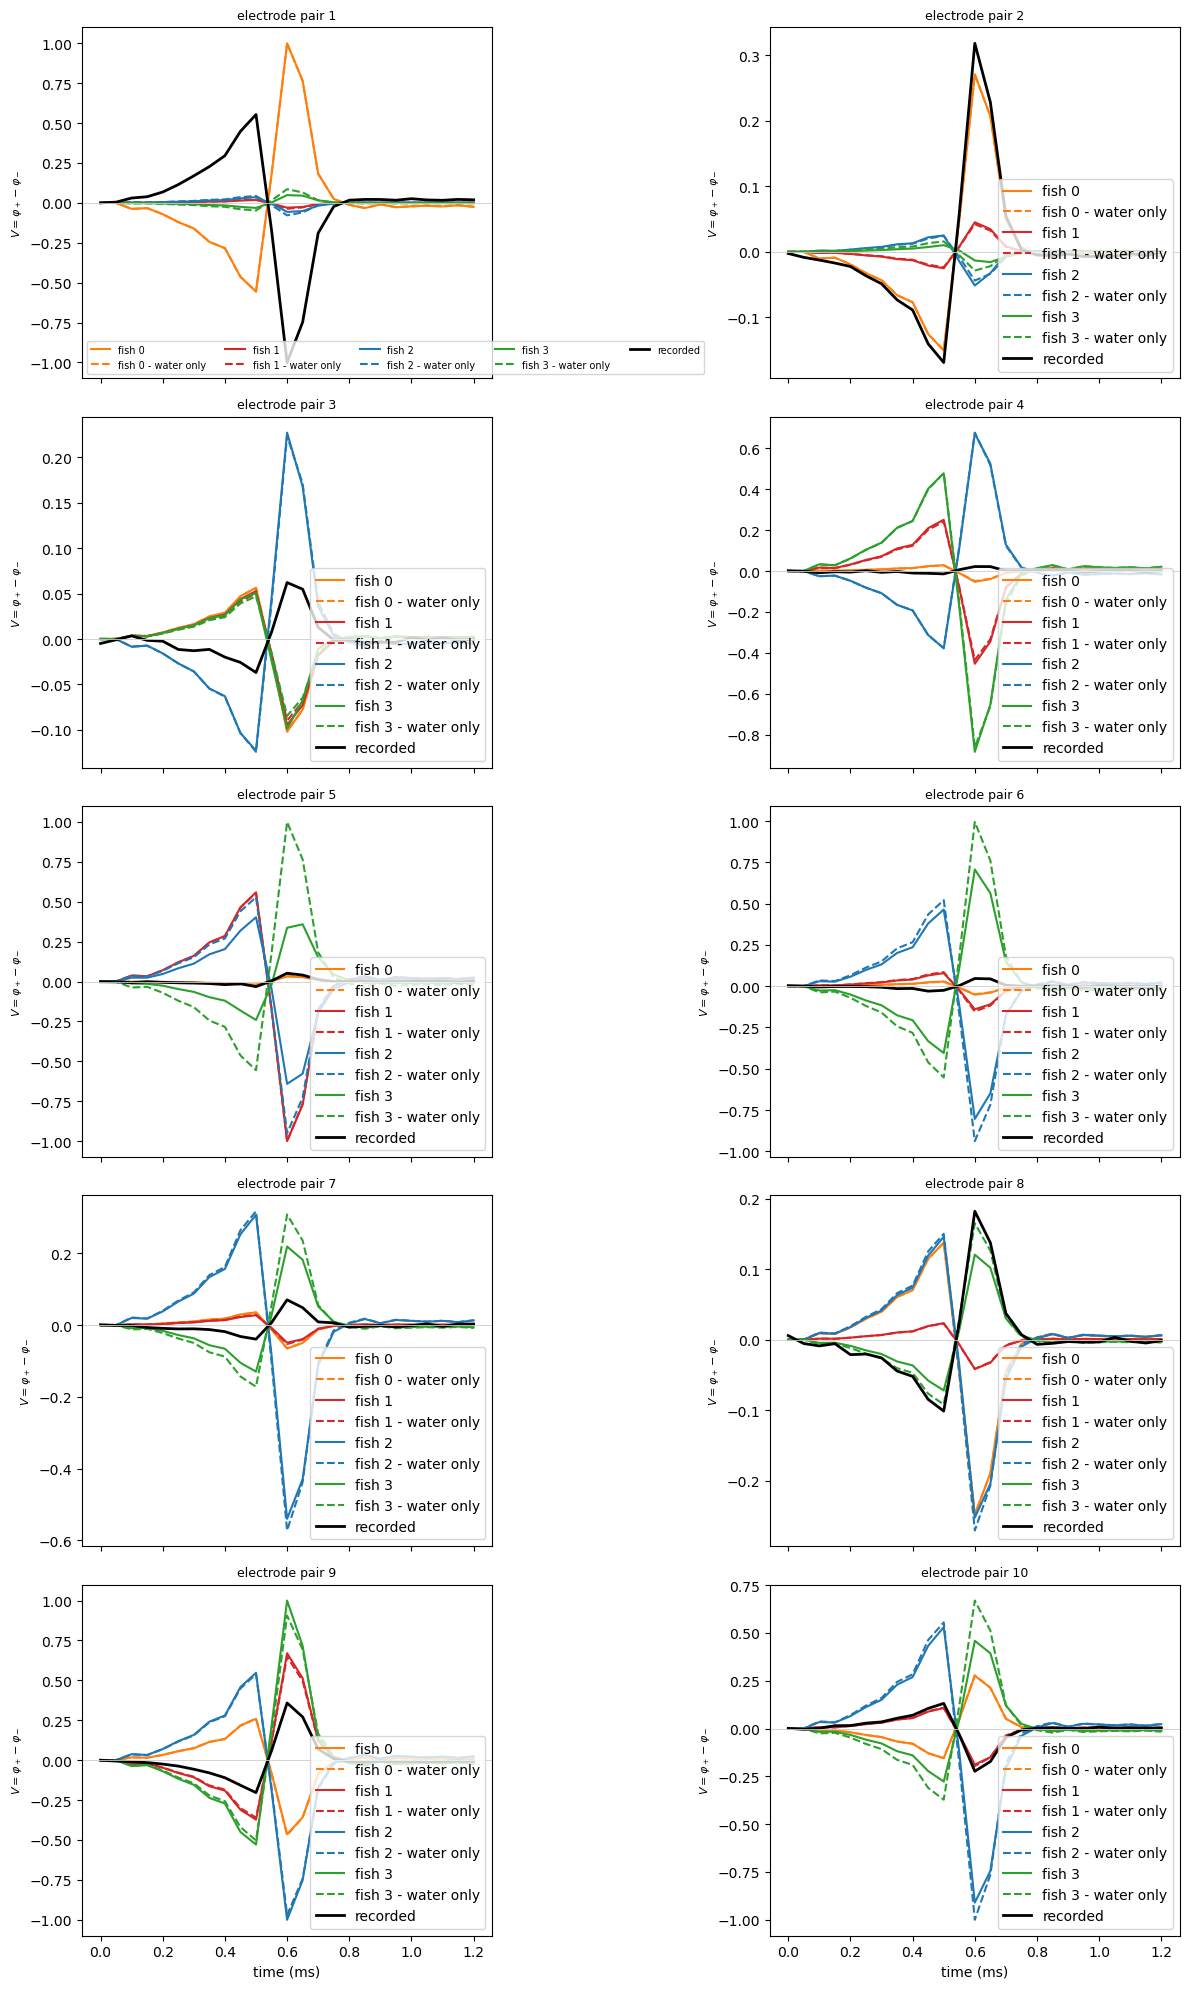

In [114]:
# --- plot: all 4 fish (simulated) vs recorded, one subplot per electrode pair ---
npair = len(pairs)
ncol = 2; nrow = int(np.ceil(npair/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 4*nrow), sharex=True)
colors_fish = ['tab:orange','tab:red','tab:blue','tab:green']
for ax, (pid, _, _) in zip(axes.ravel(), pairs):
    for sf in range(4):
        ax.plot(t_ms, V_sim_all[sf][pid], lw=1.5, color=colors_fish[sf], label=f"fish {sf}")
        ax.plot(t_ms, V_sim_water_all[sf][pid], ls='--', lw=1.5, color=colors_fish[sf], label=f"fish {sf} - water only")
    ax.plot(t_ms, V_rec_pairs[pid], lw=2, color='black', label="recorded")
    ax.axhline(0, color='0.8', lw=0.6)
    ax.set_title(f"electrode pair {pid}", fontsize=9)
    ax.set_ylabel(r"$V=\varphi_+-\varphi_-$", fontsize=8)
    ax.legend(loc='lower right')

for ax in axes.ravel()[npair:]: ax.axis("off")
axes.ravel()[0].legend(fontsize=7, ncol=5)
for ax in axes.ravel()[-ncol:]:
    if ax.axison: ax.set_xlabel("time (ms)")
plt.tight_layout(); plt.show()

In [14]:
source_fish = 0
sigma, eps, layers = material_layers(fish_mask, N, skip=source_fish, **MAT)

src_cells = mask_to_grid(fish_mask[source_fish], N)
print("source fish in layers dict?", source_fish in layers)            # -> False (skipped)
print("sigma on source-fish cells unique:", np.unique(sigma[src_cells]))  # -> [1.0] only (water)
print("eps   on source-fish cells max   :", eps[src_cells].max())      # -> 0.0

source fish in layers dict? False
sigma on source-fish cells unique: [1.]
eps   on source-fish cells max   : 0.0


# Interactive Plot

In [38]:
import ipywidgets as widgets
from IPython.display import display

source_fish = 0
delta_h = 0.5
h = 1.0/(N-1); g = np.linspace(0, 1, N)

midline = fish_midline_from_mask(fish_mask[source_fish])
positions, currents = multipole_sources(midline, n=100, I0=1.0)
b_unit = build_multipole_b(positions, currents, h, N)
pairs = load_electrode_pairs('data/electrodes_signed_px_coord_2024-02-13.csv')
cmap = plt.cm.tab10
occ_with = occupancy_field(fish_mask, N, skip=source_fish)

def _gammas(omega):
    gw = MAT['sigma_water']    + 1j*omega*MAT['eps_water']
    gs = MAT['sigma_skin']     + 1j*omega*MAT['eps_skin']
    gi = MAT['sigma_interior'] + 1j*omega*MAT['eps_interior']
    return gw, gs, gi

psi_fish = np.zeros((len(Ihat), N*N), complex)
for k in keep:
    gw, gs, gi = _gammas(om[k])
    psi_fish[k] = solve_potential(build_A_shell(occ_with, N, delta_h, gw, gs, gi), b_unit)
phi_fish_t = np.fft.irfft(Ihat[:, None] * psi_fish, n=n_t, axis=0)

It = I_rec - I_rec.mean()
vP = np.percentile(np.abs(phi_fish_t[:n_t//2]), 99.5)
srcp, snkp = currents > 0, currents < 0

def _outline(ax):
    for f, m in enumerate(fish_mask):
        if not m.any(): continue
        is_src = (f == source_fish)
        ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5], zorder=4,
                   colors=["#FFD400" if is_src else "lime"],
                   linewidths=1.8 if is_src else 1.0, linestyles="--" if is_src else "-")

In [39]:
def draw_frame(ti):
    phi = to_grid(phi_fish_t[ti], N)
    dpx, dpy = np.gradient(phi, h); Ex, Ey = -dpx, -dpy

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im0 = ax.imshow(phi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-vP, vmax=vP)
    if np.ptp(phi) > 0:
        ax.streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.4, arrowsize=0.5)
    _outline(ax)
    ax.plot(positions[:,0], positions[:,1], "-", color="0.2", lw=1, zorder=5)
    ax.scatter(*positions[srcp].T, c="#C0392B", s=14, ec="k", lw=0.3, zorder=6)
    ax.scatter(*positions[snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5, zorder=6)
    fig.colorbar(im0, ax=ax, fraction=0.046, label=r"$\varphi$")
    for k, (pid, pp, pm) in enumerate(pairs):
        c = cmap(k % 10)
        ax.scatter(pp[0], pp[1], marker='o', s=70, c=[c], ec='k', lw=0.6, zorder=5)
        ax.scatter(pm[0], pm[1], marker='x', s=70, c=[c], lw=2.0, zorder=5)
        ax.plot([pp[0],pm[0]], [pp[1],pm[1]], color=c, lw=0.8, alpha=0.5, zorder=4)
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"source fish {source_fish} — frame {ti}, t={ti*dt*1e3:.2f} ms, "
                 f"I(t)={It[ti]:+.3f} ({pct_of_peak(It[ti])})", fontsize=10)
    plt.tight_layout(); plt.show()

widgets.interact(draw_frame,
                 ti=widgets.IntSlider(min=0, max=n_t-1, step=1, value=0,
                                      description="frame", continuous_update=False));

interactive(children=(IntSlider(value=0, continuous_update=False, description='frame', max=24), Output()), _do…

In [41]:
import matplotlib.animation as animation

delta_h = 0.5
h = 1.0/(N-1); g = np.linspace(0, 1, N)
pairs = load_electrode_pairs('data/electrodes_signed_px_coord_2024-02-13.csv')
cmap = plt.cm.tab10
It = I_rec - I_rec.mean()

def _gammas(omega):
    gw = MAT['sigma_water']    + 1j*omega*MAT['eps_water']
    gs = MAT['sigma_skin']     + 1j*omega*MAT['eps_skin']
    gi = MAT['sigma_interior'] + 1j*omega*MAT['eps_interior']
    return gw, gs, gi

for source_fish in range(4):
    # --- field for this source fish (your solve) ---
    midline = fish_midline_from_mask(fish_mask[source_fish])
    positions, currents = multipole_sources(midline, n=100, I0=1.0)
    b_unit = build_multipole_b(positions, currents, h, N)
    occ_with = occupancy_field(fish_mask, N, skip=source_fish)

    psi_fish = np.zeros((len(Ihat), N*N), complex)
    for k in keep:
        gw, gs, gi = _gammas(om[k])
        psi_fish[k] = solve_potential(build_A_shell(occ_with, N, delta_h, gw, gs, gi), b_unit)
    phi_fish_t = np.fft.irfft(Ihat[:, None] * psi_fish, n=n_t, axis=0)

    vP = np.percentile(np.abs(phi_fish_t[:n_t//2]), 99.5)
    srcp, snkp = currents > 0, currents < 0

    def _outline(ax):
        for f, m in enumerate(fish_mask):
            if not m.any(): continue
            is_src = (f == source_fish)
            ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5], zorder=4,
                       colors=["#FFD400" if is_src else "lime"],
                       linewidths=1.8 if is_src else 1.0, linestyles="--" if is_src else "-")

    # --- static figure setup ---
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im0 = ax.imshow(to_grid(phi_fish_t[0], N).T, origin="lower", extent=[0,1,0,1],
                    cmap="RdBu_r", vmin=-vP, vmax=vP)
    fig.colorbar(im0, ax=ax, fraction=0.046, label=r"$\varphi$")
    _outline(ax)
    ax.plot(positions[:,0], positions[:,1], "-", color="0.2", lw=1, zorder=5)
    ax.scatter(*positions[srcp].T, c="#C0392B", s=14, ec="k", lw=0.3, zorder=6)
    ax.scatter(*positions[snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5, zorder=6)
    for k, (pid, pp, pm) in enumerate(pairs):
        c = cmap(k % 10)
        ax.scatter(pp[0], pp[1], marker='o', s=70, c=[c], ec='k', lw=0.6, zorder=5)
        ax.scatter(pm[0], pm[1], marker='x', s=70, c=[c], lw=2.0, zorder=5)
        ax.plot([pp[0],pm[0]], [pp[1],pm[1]], color=c, lw=0.8, alpha=0.5, zorder=4)
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    title = ax.set_title("")
    stream = {"s": None}

    def update(ti, _sf=source_fish, _phi=phi_fish_t, _srcp=srcp, _snkp=snkp):
        phi = to_grid(_phi[ti], N)
        im0.set_data(phi.T)
        if stream["s"] is not None:
            stream["s"].lines.remove()
            for art in ax.patches[:]: art.remove()
        if np.ptp(phi) > 0:
            dpx, dpy = np.gradient(phi, h); Ex, Ey = -dpx, -dpy
            stream["s"] = ax.streamplot(g, g, Ex.T, Ey.T, color="k",
                                        density=0.7, linewidth=0.4, arrowsize=0.5)
        title.set_text(f"source fish {_sf} — frame {ti}, t={ti*dt*1e3:.2f} ms, "
                       f"I(t)={It[ti]:+.3f} ({pct_of_peak(It[ti])})")
        return [im0]

    anim = animation.FuncAnimation(fig, update, frames=n_t, interval=120, blit=False)
    fname = f"eod_field_fish{source_fish}.mp4"
    anim.save(fname, writer=animation.FFMpegWriter(fps=8, bitrate=2000), dpi=130)
    plt.close(fig)
    print("saved", fname)

saved eod_field_fish0.mp4
saved eod_field_fish1.mp4
saved eod_field_fish2.mp4
saved eod_field_fish3.mp4
